# Hanging-Sphere Cut-Cell Convergence

This notebook is the single, auditable workflow for the planar-cap hanging-sphere study. It compares four stiffness frameworks on the same full-plus-cut active-cell support:

1. Naive full-cell Gauss stiffness on cut cells.
2. Geometric-volume-fraction-weighted full-cell Gauss stiffness.
3. QuESo quadrature stiffness.
4. NN cut-cell hybrid stiffness.

Run the cells in order: configure the study, define the geometry and solver, run the guarded solve cell for missing or stale checkpoints, run the archive/cache audit, then run the validated convergence graph. The graph refuses to run unless every framework archive matches QuESo's active-cell support at every plotted resolution.

In [127]:
from pathlib import Path
import gc
import os
import sys
import time

import numpy as np
import pandas as pd
import torch

root = Path.cwd().resolve()
while root != root.parent and not (root / 'clean_simulation').exists():
    root = root.parent
if not (root / 'clean_simulation').exists():
    raise RuntimeError('Run this notebook from the repository root or a descendant directory.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

SUPPORT_OUTPUT_NAMES = {'planar_cap': 'planar_cap_plane_hard_constraints', 'smooth_foundation': 'smooth_foundation'}
# when intentionally running an isolated study elsewhere.
OUTPUT_DIR = Path(os.environ.get(
    'HANGING_SPHERE_OUTPUT_DIR',
    root / 'clean_simulation' / 'outputs' / 'sphere_displacement_convergence_physical_fixed_support_local',
)).expanduser().resolve()
SUPPORT_MODE = os.environ.get('HANGING_SPHERE_SUPPORT_MODE', 'smooth_foundation').strip().lower()
if SUPPORT_MODE not in SUPPORT_OUTPUT_NAMES:
    raise ValueError(f'Unknown HANGING_SPHERE_SUPPORT_MODE={SUPPORT_MODE!r}.')
SUPPORT_OUTPUT_DIR = OUTPUT_DIR / SUPPORT_OUTPUT_NAMES[SUPPORT_MODE]
PLANAR_CAP_OUTPUT_DIR = OUTPUT_DIR / SUPPORT_OUTPUT_NAMES['planar_cap']
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUPPORT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLANAR_CAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESOLUTION_SCHEDULE = tuple(int(value) for value in os.environ.get(
    'HANGING_SPHERE_RESOLUTIONS', '8,16,32,64,128',
).split(','))
REFERENCE_RESOLUTION = int(os.environ.get('HANGING_SPHERE_REFERENCE_RESOLUTION', '128'))
if REFERENCE_RESOLUTION not in RESOLUTION_SCHEDULE:
    raise ValueError('HANGING_SPHERE_REFERENCE_RESOLUTION must be included in HANGING_SPHERE_RESOLUTIONS.')

print(f'Canonical output directory: {OUTPUT_DIR}')
print(f'Planar-cap archive directory: {PLANAR_CAP_OUTPUT_DIR}')
print(f'Resolution schedule: {RESOLUTION_SCHEDULE}; QuESo reference: {REFERENCE_RESOLUTION}^3')

Canonical output directory: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\smooth_radial_foundation_sub9
Planar-cap archive directory: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\smooth_radial_foundation_sub9\planar_cap_plane_hard_constraints
Resolution schedule: (8, 16, 32, 64, 128); QuESo reference: 128^3


In [45]:
# Editor-safe local smooth-foundation study through 128^3.
os.environ['HANGING_SPHERE_OUTPUT_DIR'] = str(
    root / 'clean_simulation' / 'outputs' / 'sphere_displacement_convergence_queso_inner_cells_local'
)
os.environ['HANGING_SPHERE_SUPPORT_MODE'] = 'smooth_foundation'
os.environ['HANGING_SPHERE_DEVICE'] = 'cpu'
os.environ['HANGING_SPHERE_RESOLUTIONS'] = '8,16,32,64,128'
os.environ['HANGING_SPHERE_REFERENCE_RESOLUTION'] = '128'
os.environ['HANGING_SPHERE_RUN_SOLVES'] = '0'
print(f"Local study output: {os.environ['HANGING_SPHERE_OUTPUT_DIR']}")
print('Configured smooth foundation on CPU: N=8, 16, 32, 64, 128; QuESo 128^3 reference.')

Local study output: C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local
Configured smooth foundation on CPU: N=8, 16, 32, 64, 128; QuESo 128^3 reference.


In [128]:
# Runtime dependencies and solver configuration used by every remaining cell.
SOLVE_DEVICE = os.environ.get('HANGING_SPHERE_DEVICE', 'cuda' if torch.cuda.is_available() else 'cpu')
CPU_THREADS = int(os.environ.get('HANGING_SPHERE_CPU_THREADS', min(6, os.cpu_count() or 1)))
RUN_SOLVES = os.environ.get('HANGING_SPHERE_RUN_SOLVES', '0') == '1'
CG_MAX_ITER = int(os.environ.get('HANGING_SPHERE_CG_MAX_ITER', '4000'))
SOLVE_DTYPE = getattr(torch, os.environ.get('HANGING_SPHERE_DTYPE', 'float32'))
if SOLVE_DEVICE == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('HANGING_SPHERE_DEVICE=cuda was requested but CUDA is unavailable.')
torch.set_num_threads(CPU_THREADS)
try:
    torch.set_num_interop_threads(1)
except RuntimeError:
    pass

queso_python_path = root / 'QuESo' / 'out' / 'install' / ('win' if os.name == 'nt' else 'linux')
if queso_python_path.exists() and str(queso_python_path) not in sys.path:
    sys.path.insert(0, str(queso_python_path))
if os.name == 'nt' and hasattr(os, 'add_dll_directory') and queso_python_path.exists():
    os.add_dll_directory(str(queso_python_path))

from clean_simulation.bootstrap import configure_legacy_imports
configure_legacy_imports(root)
from clean_simulation.case import build_case_from_stl
from clean_simulation.internal_fem_kernel.runtime.assembly_ops import assemble_force_base
from clean_simulation.internal_fem_kernel.runtime.matrix_free import (
    StructuredCompressedMatrixFreeElasticityOperator,
    solve_matrix_free_cg,
)
from clean_simulation.internal_nn_runtime.cutcell_bridge import compute_nn_cutcell_stiffness, prepare_nn_inputs
from clean_simulation.nn_runtime import load_nn_engine
from internal_fem_kernel.assembly.stiffness import StiffnessAssembly
from internal_fem_kernel.core.grid_indexing import active_element_nodes

ALL_FRAMEWORKS = {
    'naive': 'Naive full-cell Gauss',
    'weighted': 'Geometric-volume-fraction weighted Gauss',
    'queso': 'QuESo quadrature',
    'nn': 'NN-cut-cell hybrid',
}
requested_frameworks = tuple(name.strip() for name in os.environ.get(
    'HANGING_SPHERE_FRAMEWORKS', ','.join(ALL_FRAMEWORKS),
).split(',') if name.strip())
unknown_frameworks = set(requested_frameworks) - set(ALL_FRAMEWORKS)
if unknown_frameworks or not requested_frameworks:
    raise ValueError(f'Invalid HANGING_SPHERE_FRAMEWORKS: {requested_frameworks}')
FRAMEWORKS = {name: ALL_FRAMEWORKS[name] for name in requested_frameworks}
FRAMEWORK_COLORS = {'naive': '#b94732', 'weighted': '#c98b1b', 'queso': '#247b74', 'nn': '#315c99'}
NN_CHECKPOINT = root / 'clean_simulation' / 'outputs' / 'checkpoints' / 'source_sdf_rebuilt_queso_d10_f1024_all_crystals_10h.pt'
SPHERE_OVERRIDES = {
    'grid': {'bounds': [[-9.0, -9.0, -9.0], [9.0, 9.0, 9.0]]},
    'material': {'E': 1.0e6, 'nu': 0.3, 'density': 1.0},
    'integration': {'poly_order': 1, 'gauss_order': 2, 'moment_fitting_residual': 1.0e-8},
    'loads': {'gravity': [0.0, 0.0, -98.1]},
    'bc': {'top_cap_fraction': 0.05, 'constraint_axis': 2, 'constraint_side': 'max'},
}
print(f'Device: {SOLVE_DEVICE}; CPU threads: {torch.get_num_threads()}; run solves: {RUN_SOLVES}')
print(f'Frameworks: {", ".join(FRAMEWORKS)}')

Device: cpu; CPU threads: 6; run solves: False
Frameworks: naive, weighted, queso, nn


In [49]:
# Select the fixed-support convergence study used by the cells below.
# Override the schedule/reference through the environment for editor-safe local studies.
RESOLUTION_SCHEDULE = tuple(int(value) for value in os.environ.get(
    'HANGING_SPHERE_RESOLUTIONS', '8,16,32,64,128,256',
).split(','))
REFERENCE_RESOLUTION = int(os.environ.get(
    'HANGING_SPHERE_REFERENCE_RESOLUTION', str(max(RESOLUTION_SCHEDULE)),
))
if REFERENCE_RESOLUTION not in RESOLUTION_SCHEDULE:
    raise ValueError('REFERENCE_RESOLUTION must be part of RESOLUTION_SCHEDULE.')
print(
    f'Configured convergence study: N={", ".join(map(str, RESOLUTION_SCHEDULE))}; '
    f'QuESo {REFERENCE_RESOLUTION}^3 is reference-only.'
)

Configured convergence study: N=8, 16, 32, 64, 128; QuESo 128^3 is reference-only.


In [121]:
def build_hard_constraint_problem(resolution):
    overrides = {**SPHERE_OVERRIDES, 'grid': {**SPHERE_OVERRIDES['grid'], 'resolution': [resolution] * 3}}
    work_dir = OUTPUT_DIR / f'queso_matrix_free_{resolution}cubed'
    stl_path = ensure_physical_sphere_stl(work_dir)

    # FIX: cut_cells_only=False, not True. compute_element_matrices_from_queso_points
    # is the SAME function that computes both trimmed and strictly-inner cells; the
    # cut_cells_only=True flag was restricting QuESo's own quadrature to trimmed
    # cells only, so the 'queso' framework never used QuESo's own integration on
    # its inner cells -- it silently reused the shared analytic full_ke below,
    # identically to naive/weighted/nn. That hides any genuine difference between
    # QuESo's own inner-cell quadrature and the idealized exact Gauss result.
    case = build_case_from_stl(
        stl_path=stl_path, overrides=overrides, workspace_root=root, work_dir=work_dir,
        queso_python_path=queso_python_path, queso_basis_order=2, cut_cells_only=False,
        integration_points_npy_path=work_dir / 'queso_all_points.npy', bounds_padding=0.0, device='cpu',
    )
    cache_path = work_dir / 'queso_all_cell_stiffness.pt'
    if cache_path.exists():
        cache = torch.load(cache_path, map_location='cpu', weights_only=True)
        queso_all_ke, queso_all_indices = cache['matrices'], cache['indices']
    else:
        queso_all_ke, queso_all_indices = StiffnessAssembly.compute_element_matrices_from_queso_points(
            grid=case.grid, material=case.material, ips=np.asarray(case.ips), poly_order=case.poly_order,
            device='cpu', element_batch_size=512,
        )
        torch.save({'matrices': queso_all_ke, 'indices': queso_all_indices}, cache_path)

    full_indices = strict_sphere_full_cells(case)

    # QuESo's own returned index set now spans BOTH inner and trimmed cells.
    # Split it against our independently-derived cut/full classification (which
    # the earlier audit already confirmed QuESo's own trimming agrees with) so we
    # know which rows of queso_all_ke correspond to inner cells vs cut cells.
    # ASSUMPTION TO VERIFY: if compute_element_matrices_from_queso_points exposes
    # QuESo's own element.IsTrimmed() flag directly (rather than us re-deriving
    # it), prefer that instead of this membership split for full self-consistency.
    is_cut_in_queso_all = torch.isin(queso_all_indices, full_indices, invert=True)
    cut_indices = queso_all_indices[is_cut_in_queso_all]
    queso_cut_ke = queso_all_ke[is_cut_in_queso_all]

    is_full_in_queso_all = torch.isin(queso_all_indices, full_indices)
    queso_full_indices = queso_all_indices[is_full_in_queso_all]
    queso_full_ke = queso_all_ke[is_full_in_queso_all]

    full_indices = full_indices[~torch.isin(full_indices, cut_indices)]
    active = torch.sort(torch.cat((full_indices, cut_indices))).values

    # Shared analytic full_ke -- still correct and used as-is for naive/weighted/nn,
    # since exact affine Gauss integration is exact for a full hex regardless of
    # framework. Only the 'queso' framework should prefer its OWN inner-cell
    # matrices (queso_full_ke) over this shared one -- see hard_constraint_cut_matrices.
    full_seed = torch.zeros(np.prod(case.grid.resolution), dtype=torch.bool)
    full_seed[full_indices[0]] = True
    full_ke = StiffnessAssembly.compute_inside_element_matrices(
        grid=case.grid, material=case.material, inside=full_seed, order=case.g_order,
        device='cpu', poly_order=case.poly_order,
    )[0][0]

    cut_force = assemble_force_base(
        grid=case.grid, active_indices=cut_indices, ips=case.ips, config=case.config,
        poly_order=case.poly_order, device='cpu',
    )
    full_force = torch.zeros_like(cut_force).reshape(-1, 3)
    full_nodes = active_element_nodes(full_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu')
    gravity = torch.as_tensor(case.config['loads']['gravity'], dtype=torch.float64) * float(case.config['material']['density'])
    full_force.index_add_(0, full_nodes.reshape(-1), gravity.repeat(len(full_indices) * 8, 1) * (case.grid.dx * case.grid.dy * case.grid.dz / 8.0))

    fractions = independent_sphere_volume_fractions(case, cut_indices)
    print(f'Independent subcell volume fractions: min={fractions.min():.6g}; median={fractions.median():.6g}; mean={fractions.mean():.6g}; max={fractions.max():.6g}')

    # NOTE: return arity is now 10, not 8 -- every call site that unpacks
    # build_hard_constraint_problem(...) needs updating to receive the two new
    # values (queso_full_ke, queso_full_indices). This includes the local-matrix-
    # audit cell fixed earlier in this session.
    return case, full_ke, full_indices, queso_cut_ke, cut_indices, active, full_force.reshape(-1) + cut_force, fractions, queso_full_ke, queso_full_indices


In [129]:
# QuESo emits [x, y, z, weight]. Normalized coordinates use weights on [0, 1]^3,
# so consumers must apply the physical-domain determinant exactly once.
def point_cell_indices_and_weights(case, point_mask=None):
    points = torch.as_tensor(np.asarray(case.ips), dtype=torch.float64)
    if point_mask is not None:
        points = points[torch.as_tensor(point_mask, dtype=torch.bool)]
    coordinates = points[:, :3]
    weights = points[:, 3]
    lower = torch.as_tensor(case.grid.bounds[0], dtype=torch.float64)
    upper = torch.as_tensor(case.grid.bounds[1], dtype=torch.float64)
    normalized = coordinates.numel() and bool(torch.all((coordinates >= 0.0) & (coordinates <= 1.0)))
    if normalized:
        coordinates = lower + coordinates * (upper - lower)
        weights = weights * torch.prod(upper - lower)
    resolution = torch.as_tensor(case.grid.resolution, dtype=torch.int64)
    spacing = torch.as_tensor((case.grid.dx, case.grid.dy, case.grid.dz), dtype=torch.float64)
    ijk = torch.floor((coordinates - lower) / spacing).to(torch.int64)
    ijk = torch.minimum(torch.maximum(ijk, torch.zeros_like(ijk)), resolution - 1)
    indices = ijk[:, 0] * (resolution[1] * resolution[2]) + ijk[:, 1] * resolution[2] + ijk[:, 2]
    return indices, weights


def physical_cell_weights(case):
    cell_count = int(np.prod(case.grid.resolution))
    indices, weights = point_cell_indices_and_weights(case)
    if not len(indices):
        return torch.zeros(cell_count, dtype=torch.float64)
    volumes = torch.bincount(indices, weights=weights, minlength=cell_count)
    cell_volume = case.grid.dx * case.grid.dy * case.grid.dz
    return (volumes / cell_volume).clamp(0.0, 1.0)


def report_cut_volume_fractions(case, cut_indices):
    fractions = physical_cell_weights(case)[cut_indices]
    if not bool(torch.isfinite(fractions).all()):
        raise RuntimeError('Cut-cell volume fractions contain non-finite values.')
    print(
        f'Cut-cell volume fractions: min={fractions.min():.6g}; '
        f'median={fractions.median():.6g}; mean={fractions.mean():.6g}; max={fractions.max():.6g}'
    )
    return fractions


print('Loaded authoritative physical QuESo point and volume-fraction helpers.')

Loaded authoritative physical QuESo point and volume-fraction helpers.


In [130]:
def phase(message, started_at=None):
    elapsed = '' if started_at is None else f' [{time.perf_counter() - started_at:.1f}s]'
    print(f'[hanging-sphere] {message}{elapsed}', flush=True)


def active_node_ids(active_cells, resolution):
    cells = np.asarray(active_cells, dtype=np.int64)
    node_side = resolution + 1
    i = cells // (resolution * resolution)
    j = (cells // resolution) % resolution
    k = cells % resolution
    base = (i * node_side + j) * node_side + k
    offsets = np.array((0, node_side * node_side, node_side * node_side + node_side, node_side, 1,
                        node_side * node_side + 1, node_side * node_side + node_side + 1, node_side + 1))
    return np.unique((base[:, None] + offsets).reshape(-1))


def strict_sphere_full_cells(case):
    nx, ny, nz = map(int, case.grid.resolution)
    sphere = case.config.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = np.asarray(sphere['center'], dtype=np.float64)
    radius_squared = float(sphere['radius']) ** 2
    lower = np.asarray(case.grid.bounds[0], dtype=np.float64)
    spacing = np.asarray((case.grid.dx, case.grid.dy, case.grid.dz), dtype=np.float64)
    y = lower[1] + np.arange(ny + 1) * spacing[1]
    z = lower[2] + np.arange(nz + 1) * spacing[2]
    yy, zz = np.meshgrid(y, z, indexing='ij')
    slabs = []
    for i in range(nx):
        x0 = lower[0] + i * spacing[0]
        x1 = x0 + spacing[0]
        distance_squared = np.maximum((x0 - center[0]) ** 2, (x1 - center[0]) ** 2)
        distance_squared += np.maximum((yy[:-1, :-1] - center[1]) ** 2, (yy[1:, 1:] - center[1]) ** 2)
        distance_squared += np.maximum((zz[:-1, :-1] - center[2]) ** 2, (zz[1:, 1:] - center[2]) ** 2)
        local = np.flatnonzero(distance_squared < radius_squared).astype(np.int64)
        if local.size:
            slabs.append(local + i * ny * nz)
    return torch.from_numpy(np.concatenate(slabs) if slabs else np.empty(0, dtype=np.int64))


print('Loaded shared planar-cap utilities.')

Loaded shared planar-cap utilities.


In [131]:
def independent_sphere_volume_fractions(
    case,
    cut_indices,
    quadrature_order=12,
    chunk_size=16384,
):
    """
    Fast sphere/cell volume fractions using analytic z integration and
    tensor-product Gauss-Legendre quadrature in x/y.

    Completely outside cells -> exactly 0
    Completely inside cells  -> exactly 1
    Boundary cells           -> numerical integration of the exact
                                 spherical z cross-section

    Parameters
    ----------
    case : simulation case
    cut_indices : 1-D tensor of flattened cell indices
    quadrature_order : Gauss-Legendre order in x and y
    chunk_size : number of cells processed simultaneously

    Returns
    -------
    torch.Tensor
        Volume fraction for each cell in cut_indices.
    """
    import numpy as np

    dtype = torch.float64
    device = cut_indices.device

    # --------------------------------------------------------------
    # Sphere
    # --------------------------------------------------------------
    sphere = case.config.get(
        "sphere",
        {
            "center": (0.0, 0.0, 0.0),
            "radius": 7.5,
        },
    )

    center = torch.as_tensor(
        sphere["center"],
        dtype=dtype,
        device=device,
    )

    radius = float(sphere["radius"])
    radius_squared = radius * radius

    # --------------------------------------------------------------
    # Grid
    # --------------------------------------------------------------
    spacing = torch.as_tensor(
        (
            case.grid.dx,
            case.grid.dy,
            case.grid.dz,
        ),
        dtype=dtype,
        device=device,
    )

    lower = torch.as_tensor(
        case.grid.bounds[0],
        dtype=dtype,
        device=device,
    )

    nx, ny, nz = map(int, case.grid.resolution)

    dx, dy, dz = spacing
    cell_volume = dx * dy * dz

    # --------------------------------------------------------------
    # Gauss-Legendre points/weights.
    #
    # IMPORTANT:
    # leggauss() returns:
    #
    #     (points, weights)
    #
    # --------------------------------------------------------------
    points_np, weights_np = np.polynomial.legendre.leggauss(
        quadrature_order
    )

    points = torch.as_tensor(
        points_np,
        dtype=dtype,
        device=device,
    )

    weights = torch.as_tensor(
        weights_np,
        dtype=dtype,
        device=device,
    )

    # Tensor-product quadrature in x/y.
    gx, gy = torch.meshgrid(
        points,
        points,
        indexing="ij",
    )

    gwx, gwy = torch.meshgrid(
        weights,
        weights,
        indexing="ij",
    )

    gx = gx.reshape(1, -1)
    gy = gy.reshape(1, -1)
    gw = (gwx * gwy).reshape(1, -1)

    # --------------------------------------------------------------
    # Output
    # --------------------------------------------------------------
    n_cells = cut_indices.numel()

    fractions = torch.empty(
        n_cells,
        dtype=dtype,
        device=device,
    )

    # --------------------------------------------------------------
    # Process in chunks.
    # --------------------------------------------------------------
    for start in range(0, n_cells, chunk_size):
        end = min(start + chunk_size, n_cells)

        indices = cut_indices[start:end].to(torch.int64)

        # ----------------------------------------------------------
        # Flattened index -> i,j,k
        # ----------------------------------------------------------
        i = indices // (ny * nz)
        j = (indices // nz) % ny
        k = indices % nz

        ijk = torch.stack(
            (i, j, k),
            dim=1,
        ).to(dtype)

        cell_lower = lower + ijk * spacing
        cell_upper = cell_lower + spacing

        xmin = cell_lower[:, 0]
        ymin = cell_lower[:, 1]
        zmin = cell_lower[:, 2]

        xmax = cell_upper[:, 0]
        ymax = cell_upper[:, 1]
        zmax = cell_upper[:, 2]

        # ----------------------------------------------------------
        # Exact outside classification.
        #
        # Minimum distance from sphere center to box.
        # ----------------------------------------------------------
        dmin = torch.where(
            center < cell_lower,
            cell_lower - center,
            torch.where(
                center > cell_upper,
                center - cell_upper,
                torch.zeros_like(cell_lower),
            ),
        )

        min_dist_squared = torch.sum(
            dmin * dmin,
            dim=1,
        )

        outside = min_dist_squared > radius_squared

        # ----------------------------------------------------------
        # Exact inside classification.
        #
        # Maximum distance is at the farthest box corner.
        # ----------------------------------------------------------
        dmax = torch.maximum(
            torch.abs(cell_lower - center),
            torch.abs(cell_upper - center),
        )

        max_dist_squared = torch.sum(
            dmax * dmax,
            dim=1,
        )

        inside = max_dist_squared <= radius_squared

        boundary = ~(outside | inside)

        # Exact values for fully outside/inside cells.
        chunk_fractions = torch.zeros(
            indices.shape[0],
            dtype=dtype,
            device=device,
        )

        chunk_fractions[inside] = 1.0

        # ----------------------------------------------------------
        # Integrate only boundary cells.
        # ----------------------------------------------------------
        boundary_ids = torch.nonzero(
            boundary,
            as_tuple=False,
        ).flatten()

        if boundary_ids.numel() > 0:

            bxmin = xmin[boundary_ids]
            bxmax = xmax[boundary_ids]

            bymin = ymin[boundary_ids]
            bymax = ymax[boundary_ids]

            bzmin = zmin[boundary_ids]
            bzmax = zmax[boundary_ids]

            # ------------------------------------------------------
            # Gauss points mapped from [-1,1] to each cell.
            # ------------------------------------------------------
            x = (
                0.5 * (bxmax - bxmin)[:, None] * gx
                + 0.5 * (bxmax + bxmin)[:, None]
            )

            y = (
                0.5 * (bymax - bymin)[:, None] * gy
                + 0.5 * (bymax + bymin)[:, None]
            )

            # ------------------------------------------------------
            # Sphere cross-section.
            #
            # z = cz +/- sqrt(R² - dx² - dy²)
            # ------------------------------------------------------
            sphere_dx = x - center[0]
            sphere_dy = y - center[1]

            remaining = (
                radius_squared
                - sphere_dx * sphere_dx
                - sphere_dy * sphere_dy
            )

            valid = remaining > 0.0

            half_height = torch.sqrt(
                torch.clamp_min(remaining, 0.0)
            )

            sphere_zmin = center[2] - half_height
            sphere_zmax = center[2] + half_height

            # ------------------------------------------------------
            # Intersection with cell's z interval.
            # ------------------------------------------------------
            intersection_zmin = torch.maximum(
                sphere_zmin,
                bzmin[:, None],
            )

            intersection_zmax = torch.minimum(
                sphere_zmax,
                bzmax[:, None],
            )

            z_length = torch.clamp_min(
                intersection_zmax - intersection_zmin,
                0.0,
            )

            # No sphere exists at this x,y.
            z_length = torch.where(
                valid,
                z_length,
                torch.zeros_like(z_length),
            )

            # ------------------------------------------------------
            # 2-D Gauss-Legendre integration.
            #
            # Integral:
            #
            # V = ∫∫ z_length(x,y) dx dy
            #
            # Jacobian = dx/2 * dy/2
            # ------------------------------------------------------
            volume = torch.sum(
                z_length * gw,
                dim=1,
            )

            volume *= (
                0.25
                * (bxmax - bxmin)
                * (bymax - bymin)
            )

            boundary_fraction = volume / cell_volume

            # Only protects against floating-point roundoff.
            boundary_fraction = boundary_fraction.clamp(
                0.0,
                1.0,
            )

            chunk_fractions[boundary_ids] = boundary_fraction

        fractions[start:end] = chunk_fractions

    return fractions

In [132]:
# Reuse a geometrically valid cached surface when QuESo cache files already exist.
# This makes local reruns debuggable when PyQuESo is unavailable: cache invalidation
# is explicit, rather than caused by a tessellation-count preference.
def ensure_physical_sphere_stl(work_dir):
    import trimesh

    sphere = SPHERE_OVERRIDES.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = np.asarray(sphere['center'], dtype=np.float64)
    radius = float(sphere['radius'])
    stl_path = work_dir / 'study_geometry_surface.stl'
    expected_bounds = np.vstack((center - radius, center + radius))
    cache_paths = (
        work_dir / 'queso_cut_points.npy',
        work_dir / 'queso_cut_stiffness.pt',
    )

    if stl_path.is_file():
        mesh = trimesh.load(stl_path, force='mesh')
        if np.allclose(mesh.bounds, expected_bounds, atol=1.0e-8, rtol=0.0):
            print(f'Reusing cached physical sphere surface and QuESo artifacts in {work_dir.name}.')
            return stl_path
        if any(path.exists() for path in cache_paths):
            raise RuntimeError(
                f'{work_dir} has QuESo cache files but its surface bounds do not match the configured sphere. '
                'Move or delete that cache directory explicitly before rebuilding it.'
            )

    if any(path.exists() for path in cache_paths):
        raise RuntimeError(
            f'{work_dir} has QuESo cache files without a geometrically valid surface. '
            'Recover the matching study_geometry_surface.stl or delete the cache directory explicitly.'
        )

    work_dir.mkdir(parents=True, exist_ok=True)
    subdivisions = int(os.environ.get('HANGING_SPHERE_SURFACE_SUBDIVISIONS', '6'))
    trimesh.creation.icosphere(subdivisions=subdivisions, radius=radius).export(stl_path)
    print(f'Created physical radius-{radius:g} sphere surface with {20 * 4 ** subdivisions:,} faces.')
    return stl_path


print('Installed cache-preserving physical-sphere surface validation.')

Installed cache-preserving physical-sphere surface validation.


In [137]:
import inspect

print(inspect.getsource(framework_body_force))

def framework_body_force(case, full_indices, cut_indices):
    cut_force = assemble_force_base(
        grid=case.grid, active_indices=cut_indices, ips=case.ips, config=case.config,
        poly_order=case.poly_order, device='cpu',
    )
    full_force = torch.zeros_like(cut_force).reshape(-1, 3)
    if len(full_indices):
        full_nodes = active_element_nodes(
            full_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu',
        )
        gravity = torch.as_tensor(case.config['loads']['gravity'], dtype=torch.float64)
        gravity *= float(case.config['material']['density'])
        full_force.index_add_(
            0, full_nodes.reshape(-1),
            gravity.repeat(len(full_indices) * 8, 1) * (case.grid.dx * case.grid.dy * case.grid.dz / 8.0),
        )
    return full_force.reshape(-1) + cut_force



## Solve And Validation

Set `HANGING_SPHERE_SUPPORT_MODE=planar_cap` and `HANGING_SPHERE_RUN_SOLVES=1` to regenerate missing or stale checkpoints. A checkpoint is stale when its archived active-cell IDs differ from the current full-plus-cut support, and it is automatically recomputed. The cache and archive audit below explains every blocked solve or graph before any convergence result is written.

In [109]:
PLANAR_CAP_MODE = 'planar_cap_plane_hard_constraints'
SMOOTH_FOUNDATION_MODE = 'smooth_radial_foundation'


def support_solution_path(framework, resolution):
    print(SUPPORT_OUTPUT_DIR / f'hanging_sphere_{framework}_displacement_{resolution}cubed.npz')
    return SUPPORT_OUTPUT_DIR / f'hanging_sphere_{framework}_displacement_{resolution}cubed.npz'


def planar_cap_solution_path(framework, resolution):
    return PLANAR_CAP_OUTPUT_DIR / f'hanging_sphere_{framework}_displacement_{resolution}cubed.npz'


def checkpoint_matches_shared_support(framework, resolution, expected_active_indices):
    path = support_solution_path(framework, resolution)
    if not path.is_file():
        return False
    try:
        with np.load(path, allow_pickle=False) as archive:
            archived_active_indices = np.unique(archive['active_cells'].astype(np.int64, copy=False))
    except (KeyError, OSError, ValueError):
        return False
    return np.array_equal(archived_active_indices, expected_active_indices.cpu().numpy())


def planar_cap_hard_constraint_dofs(case, active_indices):
    axis = int(case.config['bc']['constraint_axis'])
    sphere = case.config.get('sphere', {'center': (0.0, 0.0, 0.0), 'radius': 7.5})
    center = float(sphere['center'][axis])
    radius = float(sphere['radius'])
    cap_start = center + radius - 2.0 * radius * float(case.config['bc']['top_cap_fraction'])
    node_ids = torch.unique(active_element_nodes(
        active_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu',
    ).reshape(-1))
    node_side = int(case.grid.resolution[axis]) + 1
    node_axis = node_ids % node_side if axis == 2 else (node_ids // node_side) % node_side if axis == 1 else node_ids // (node_side * node_side)
    lower = float(case.grid.bounds[0][axis])
    spacing = (case.grid.dx, case.grid.dy, case.grid.dz)[axis]
    coordinates = lower + node_axis.to(torch.float64) * spacing
    cap_nodes = node_ids[torch.isclose(coordinates, torch.as_tensor(cap_start, dtype=coordinates.dtype), atol=1.0e-12, rtol=0.0)]
    if not len(cap_nodes):
        raise RuntimeError(f'Nested planar cap at {cap_start:.6f} selected no active nodes.')
    return (3 * cap_nodes[:, None] + torch.arange(3, dtype=torch.int64)).reshape(-1), cap_start


def smooth_foundation_matrix(case, active_indices, cut_indices):
    """Return the compact radial C1 foundation added to all active displacement DOFs."""
    resolution = tuple(int(value) for value in case.grid.resolution)
    node_side = resolution[0] + 1
    node_count = node_side ** 3
    cell_count = int(np.prod(resolution))
    cell_fractions = torch.zeros(cell_count, dtype=torch.float64)
    cell_fractions[active_indices] = 1.0
    cut_indices = torch.as_tensor(cut_indices, dtype=torch.int64)
    cell_fractions[cut_indices] = physical_cell_weights(case)[cut_indices]
    cell_volume = case.grid.dx * case.grid.dy * case.grid.dz
    node_ids = torch.as_tensor(active_node_ids(active_indices.numpy(), resolution[0]), dtype=torch.int64)
    node_volumes = torch.zeros(node_count, dtype=torch.float64)
    element_nodes = active_element_nodes(
        active_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu',
    )
    node_volumes.index_add_(
        0,
        element_nodes.reshape(-1),
        (cell_fractions[active_indices] * (cell_volume / 8.0)).repeat_interleave(8),
    )
    i = node_ids // (node_side * node_side)
    j = (node_ids // node_side) % node_side
    k = node_ids % node_side
    lower = torch.as_tensor(case.grid.bounds[0], dtype=torch.float64)
    spacing = torch.as_tensor((case.grid.dx, case.grid.dy, case.grid.dz), dtype=torch.float64)
    coordinates = lower + torch.stack((i, j, k), dim=1).to(torch.float64) * spacing
    radius = torch.linalg.vector_norm(coordinates, dim=1)
    taper = ((5.5 - radius) / 1.5).clamp(0.0, 1.0)
    taper = taper * taper * (3.0 - 2.0 * taper)
    diagonal = 40_000.0 * taper * node_volumes[node_ids]
    dofs = (3 * node_ids[:, None] + torch.arange(3, dtype=torch.int64)).reshape(-1)
    values = diagonal.repeat_interleave(3).to(dtype=SOLVE_DTYPE)
    return torch.sparse_coo_tensor(
        torch.stack((dofs, dofs)), values, (3 * node_count, 3 * node_count), dtype=SOLVE_DTYPE,
    ).coalesce()


def support_boundary_terms(case, active_indices, cut_indices):
    if SUPPORT_MODE == 'planar_cap':
        constrained_dofs, cap_start = planar_cap_hard_constraint_dofs(case, active_indices)
        return None, constrained_dofs, {'cap_start': cap_start}
    foundation = smooth_foundation_matrix(case, active_indices, cut_indices)
    active_nodes = int(active_node_ids(active_indices.numpy(), int(case.grid.resolution[0])).size)
    return foundation, None, {'foundation_active_nodes': active_nodes, 'foundation_stiffness': 40_000.0}


def solve_support_frameworks(resolution):
    phase(f'{resolution}^3: validating requested checkpoints against the shared support')
    (case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force,
     fractions, queso_full_ke, queso_full_indices) = build_hard_constraint_problem(resolution)
    pending = [
        framework for framework in FRAMEWORKS
        if not checkpoint_matches_shared_support(framework, resolution, active)
    ]
    if not pending:
        print(f'{resolution}^3: all {SUPPORT_MODE} checkpoints match the shared support.')
        del case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force, fractions, queso_full_ke, queso_full_indices
        gc.collect()
        return
    phase(f'{resolution}^3: preparing {", ".join(pending)} with {SUPPORT_MODE}')
    foundation, constrained_dofs, support_metadata = support_boundary_terms(case, active, queso_cut_indices)
    nn_engine = None
    if 'nn' in pending:
        nn_engine = load_nn_engine(checkpoint_path=NN_CHECKPOINT, device=SOLVE_DEVICE, dtype='float32')
    try:
        for framework in pending:
            started = time.perf_counter()
            full_indices, cut_indices, active_indices = framework_support(
                framework, case, strict_full_indices, queso_cut_indices,
            )
            if not torch.equal(active_indices, active):
                raise AssertionError(f'{framework} does not use the shared full-plus-cut active support.')
            framework_fractions = fractions if framework != 'naive' else torch.empty(0, dtype=fractions.dtype)
            cut_matrices = hard_constraint_cut_matrices(
                framework, case, full_ke, queso_cut_ke, cut_indices, framework_fractions, nn_engine,
            )
            framework_full_matrices = hard_constraint_full_matrices(
                framework, full_indices, full_ke, queso_full_ke, queso_full_indices,
            )
            if not torch.allclose(framework_full_matrices, framework_full_matrices[:1], rtol=1.0e-10, atol=1.0e-12):
                raise RuntimeError(f'{framework} has nonuniform strict-inner stiffness and cannot use the compressed operator.')
            framework_force = framework_body_force(case, full_indices, cut_indices)
            if constrained_dofs is None:
                phase(f'{framework}: {len(full_indices):,} full cells, {len(cut_indices):,} cut cells, smooth foundation on {support_metadata["foundation_active_nodes"]:,} active nodes')
            else:
                phase(f'{framework}: {len(full_indices):,} full cells, {len(cut_indices):,} cut cells, {len(constrained_dofs) // 3:,} constrained nodes at z={support_metadata["cap_start"]:.4f}')
            operator = StructuredCompressedMatrixFreeElasticityOperator(
                framework_full_matrices[0], full_indices, cut_matrices, cut_indices, tuple(case.grid.resolution), foundation,
                element_batch_size=32768, slab_cells=1, constrained_dofs=constrained_dofs,
            )
            solution, info = solve_matrix_free_cg(
                operator, framework_force, rtol=1.0e-6, atol=1.0e-8, max_iter=CG_MAX_ITER,
                check_interval=10, report_interval_seconds=30.0, max_seconds_per_iteration=None,
            )
            if not info['converged']:
                raise RuntimeError(f'{framework} {resolution}^3 solve did not converge: {info}')
            np.savez_compressed(
                support_solution_path(framework, resolution),
                u_nodes=solution.detach().cpu().numpy().reshape(-1, 3), active_cells=active_indices.numpy(),
                active_nodes=active_node_ids(active_indices.numpy(), resolution), runtime_seconds=time.perf_counter() - started,
                solver_info=np.array([info], dtype=object),
                boundary_mode=PLANAR_CAP_MODE if SUPPORT_MODE == 'planar_cap' else SMOOTH_FOUNDATION_MODE,
                support_mode=SUPPORT_MODE, **support_metadata,
            )
            phase(f'{resolution}^3 {framework} checkpoint saved: {info}', started)
            del full_indices, cut_indices, active_indices, framework_fractions, cut_matrices, framework_full_matrices, framework_force, operator, solution
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    finally:
        del nn_engine, case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force, fractions, queso_full_ke, queso_full_indices, foundation
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


if RUN_SOLVES:
    for resolution in RESOLUTION_SCHEDULE:
        solve_support_frameworks(resolution)
else:
    print('Solve launch skipped. Set HANGING_SPHERE_RUN_SOLVES=1 to compute missing checkpoints.')

Solve launch skipped. Set HANGING_SPHERE_RUN_SOLVES=1 to compute missing checkpoints.


In [110]:
# QuESo's native inner-cell integration is element-specific, so it needs a per-element operator.
class ExactElementMatrixFreeElasticityOperator:
    def __init__(self, element_matrices, active_indices, resolution, nitsche_matrix=None, constrained_dofs=None, element_batch_size=32768):
        self.device = torch.device(SOLVE_DEVICE)
        self.dtype = SOLVE_DTYPE
        self.element_matrices = torch.as_tensor(element_matrices, dtype=self.dtype, device=self.device)
        self.active_indices = torch.as_tensor(active_indices, dtype=torch.int64, device=self.device).reshape(-1)
        self.resolution = tuple(resolution)
        self.node_count = (self.resolution[0] + 1) * (self.resolution[1] + 1) * (self.resolution[2] + 1)
        self.nitsche_matrix = None if nitsche_matrix is None else nitsche_matrix.to(device=self.device, dtype=self.dtype).coalesce()
        self.constrained_dofs = None if constrained_dofs is None else torch.as_tensor(constrained_dofs, dtype=torch.int64, device=self.device).unique()
        self.element_batch_size = element_batch_size
        self.element_nodes = active_element_nodes(self.active_indices, self.resolution, poly_order=1, device=self.device)

    def matvec(self, vector):
        vector = torch.as_tensor(vector, dtype=self.dtype, device=self.device).reshape(-1)
        displacements = vector.reshape(self.node_count, 3)
        result = torch.zeros_like(displacements)
        for start in range(0, len(self.active_indices), self.element_batch_size):
            stop = min(start + self.element_batch_size, len(self.active_indices))
            nodes = self.element_nodes[start:stop]
            local_u = displacements[nodes].reshape(stop - start, 24)
            local_result = torch.bmm(self.element_matrices[start:stop], local_u.unsqueeze(-1)).squeeze(-1)
            result.index_add_(0, nodes.reshape(-1), local_result.reshape(-1, 3))
        result = result.reshape(-1)
        if self.nitsche_matrix is not None:
            result += torch.sparse.mm(self.nitsche_matrix, vector[:, None]).reshape(-1)
        if self.constrained_dofs is not None:
            result[self.constrained_dofs] = vector[self.constrained_dofs]
        return result

    def diagonal(self):
        result = torch.zeros((self.node_count, 3), dtype=self.dtype, device=self.device)
        local_diagonal = self.element_matrices.diagonal(dim1=1, dim2=2).reshape(-1, 8, 3)
        for start in range(0, len(self.active_indices), self.element_batch_size):
            stop = min(start + self.element_batch_size, len(self.active_indices))
            result.index_add_(0, self.element_nodes[start:stop].reshape(-1), local_diagonal[start:stop].reshape(-1, 3))
        result = result.reshape(-1)
        if self.nitsche_matrix is not None:
            indices = self.nitsche_matrix.indices()
            diagonal = indices[0] == indices[1]
            result.index_add_(0, indices[0, diagonal], self.nitsche_matrix.values()[diagonal])
        if self.constrained_dofs is not None:
            result[self.constrained_dofs] = 1.0
        return torch.where(result.abs() > 1.0e-20, result, torch.ones_like(result))


def solve_support_frameworks(resolution):
    phase(f'{resolution}^3: validating requested checkpoints against the shared support')
    (case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force,
     fractions, queso_full_ke, queso_full_indices) = build_hard_constraint_problem(resolution)
    pending = [framework for framework in FRAMEWORKS if not checkpoint_matches_shared_support(framework, resolution, active)]
    if not pending:
        print(f'{resolution}^3: all {SUPPORT_MODE} checkpoints match the shared support.')
        return
    foundation, constrained_dofs, support_metadata = support_boundary_terms(case, active, queso_cut_indices)
    nn_engine = load_nn_engine(checkpoint_path=NN_CHECKPOINT, device=SOLVE_DEVICE, dtype='float32') if 'nn' in pending else None
    try:
        for framework in pending:
            started = time.perf_counter()
            full_indices, cut_indices, active_indices = framework_support(framework, case, strict_full_indices, queso_cut_indices)
            cut_matrices = hard_constraint_cut_matrices(framework, case, full_ke, queso_cut_ke, cut_indices, fractions, nn_engine)
            framework_force = framework_body_force(case, full_indices, cut_indices)
            if framework == 'queso':
                full_matrices = hard_constraint_full_matrices('queso', full_indices, full_ke, queso_full_ke, queso_full_indices)
                operator = ExactElementMatrixFreeElasticityOperator(
                    torch.cat((full_matrices, cut_matrices), dim=0), torch.cat((full_indices, cut_indices), dim=0),
                    tuple(case.grid.resolution), foundation, constrained_dofs=constrained_dofs,
                )
            else:
                operator = StructuredCompressedMatrixFreeElasticityOperator(
                    full_ke, full_indices, cut_matrices, cut_indices, tuple(case.grid.resolution), foundation,
                    element_batch_size=32768, slab_cells=1, constrained_dofs=constrained_dofs,
                )
            solution, info = solve_matrix_free_cg(
                operator, framework_force, rtol=1.0e-6, atol=1.0e-8, max_iter=CG_MAX_ITER,
                check_interval=10, report_interval_seconds=30.0, max_seconds_per_iteration=None,
            )
            if not info['converged']:
                raise RuntimeError(f'{framework} {resolution}^3 solve did not converge: {info}')
            np.savez_compressed(
                support_solution_path(framework, resolution), u_nodes=solution.detach().cpu().numpy().reshape(-1, 3),
                active_cells=active_indices.numpy(), active_nodes=active_node_ids(active_indices.numpy(), resolution),
                runtime_seconds=time.perf_counter() - started, solver_info=np.array([info], dtype=object),
                boundary_mode=PLANAR_CAP_MODE if SUPPORT_MODE == 'planar_cap' else SMOOTH_FOUNDATION_MODE,
                support_mode=SUPPORT_MODE, **support_metadata,
            )
            phase(f'{resolution}^3 {framework} checkpoint saved: {info}', started)
            del cut_matrices, framework_force, operator, solution
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    finally:
        del nn_engine, case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force, fractions, queso_full_ke, queso_full_indices, foundation
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print('Installed exact per-element QuESo operator.')

Installed exact per-element QuESo operator.


In [111]:
# Diagnose why framework_full_matrices for framework='queso' is non-uniform,
# before deciding whether to loosen the tolerance or fix cell classification.

DIAGNOSTIC_RESOLUTION = 16

(case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active,
 shared_force, fractions, queso_full_ke, queso_full_indices) = build_hard_constraint_problem(DIAGNOSTIC_RESOLUTION)

# Pull QuESo's own per-cell matrices for every strict-full cell, in strict_full_indices order.
positions = torch.searchsorted(queso_full_indices, strict_full_indices)
if not torch.equal(queso_full_indices[positions], strict_full_indices):
    raise ValueError(
        "QuESo inner-cell index set does not cover all strict_full_indices; "
        "check cut_cells_only=False took effect and caches were regenerated."
    )
queso_full_matrices = queso_full_ke[positions]  # (num_full_cells, 24, 24)

# --- 1 & 2: deviation from the mean, and from the exact analytic full_ke ---
mean_matrix = queso_full_matrices.mean(dim=0, keepdim=True)
mean_norm = torch.linalg.matrix_norm(mean_matrix, ord='fro').clamp_min(torch.finfo(torch.float64).tiny)
analytic_norm = torch.linalg.matrix_norm(full_ke, ord='fro').clamp_min(torch.finfo(torch.float64).tiny)

rel_dev_from_mean = torch.linalg.matrix_norm(queso_full_matrices - mean_matrix, ord='fro') / mean_norm
rel_dev_from_analytic = torch.linalg.matrix_norm(queso_full_matrices - full_ke[None], ord='fro') / analytic_norm

def summarize(name, values):
    values_sorted, _ = torch.sort(values)
    n = len(values_sorted)
    p99_index = min(n - 1, int(round(0.99 * (n - 1))))
    print(
        f'{name}: min={values_sorted[0]:.3e}  median={values_sorted[n // 2]:.3e}  '
        f'p99={values_sorted[p99_index]:.3e}  max={values_sorted[-1]:.3e}  (n={n})'
    )

print(f'--- QuESo strict-full-cell matrix deviation at N={DIAGNOSTIC_RESOLUTION} ---')
summarize('rel_dev_from_mean    ', rel_dev_from_mean)
summarize('rel_dev_from_analytic', rel_dev_from_analytic)

NOISE_THRESHOLD = 1.0e-5  # generous ceiling for float64 quadrature/summation-order noise
is_noise = bool(rel_dev_from_mean.max() < NOISE_THRESHOLD)
print(f'\nMax relative deviation from mean is {"" if is_noise else "NOT "}consistent with pure quadrature/float noise '
      f'(threshold {NOISE_THRESHOLD:.0e}).')

# --- 3: spatial pattern -- do the worst-deviating cells cluster next to cut cells? ---
resolution = tuple(int(value) for value in case.grid.resolution)
cut_set = set(queso_cut_indices.cpu().tolist())

def cell_ijk(flat_ids, resolution):
    nx, ny, nz = resolution
    i = flat_ids // (ny * nz)
    j = (flat_ids // nz) % ny
    k = flat_ids % nz
    return torch.stack((i, j, k), dim=1)

def is_adjacent_to_cut(flat_ids, resolution, cut_set):
    nx, ny, nz = resolution
    ijk = cell_ijk(flat_ids, resolution)
    flags = torch.zeros(len(flat_ids), dtype=torch.bool)
    offsets = ((1, 0, 0), (-1, 0, 0), (0, 1, 0), (0, -1, 0), (0, 0, 1), (0, 0, -1))
    for di, dj, dk in offsets:
        ni = ijk[:, 0] + di
        nj = ijk[:, 1] + dj
        nk = ijk[:, 2] + dk
        valid = (ni >= 0) & (ni < nx) & (nj >= 0) & (nj < ny) & (nk >= 0) & (nk < nz)
        neighbor_flat = ni.clamp(0, nx - 1) * (ny * nz) + nj.clamp(0, ny - 1) * nz + nk.clamp(0, nz - 1)
        for index in torch.nonzero(valid, as_tuple=False).reshape(-1).tolist():
            if int(neighbor_flat[index]) in cut_set:
                flags[index] = True
    return flags

# Take the top 1% (or top 20, whichever is larger) most-deviating full cells.
n_full = len(strict_full_indices)
top_k = max(20, n_full // 100)
_, worst_order = torch.sort(rel_dev_from_mean, descending=True)
worst_indices_flat = strict_full_indices[worst_order[:top_k]]
worst_adjacent = is_adjacent_to_cut(worst_indices_flat, resolution, cut_set)

# Baseline: adjacency rate across ALL full cells, for comparison.
all_adjacent = is_adjacent_to_cut(strict_full_indices, resolution, cut_set)

print(f'\nAmong the top {top_k} most-deviating full cells: '
      f'{int(worst_adjacent.sum())}/{top_k} ({100.0 * worst_adjacent.float().mean():.1f}%) are adjacent to a cut cell.')
print(f'Baseline across all {n_full} strict-full cells: '
      f'{int(all_adjacent.sum())}/{n_full} ({100.0 * all_adjacent.float().mean():.1f}%) are adjacent to a cut cell.')

if is_noise:
    print('\nConclusion: deviation magnitude is consistent with quadrature/float noise. '
          "QuESo's full-cell matrices are not meaningfully different from the exact analytic result -- "
          'use the shared full_ke for the queso framework too, same as naive/weighted/nn.')
elif worst_adjacent.float().mean() > 2.0 * all_adjacent.float().mean():
    print('\nConclusion: high-deviation cells are concentrated near cut cells -- this looks like a real '
          "classification discrepancy: strict_sphere_full_cells() disagrees with QuESo's own geometry "
          'resolution for boundary-adjacent cells. These cells should likely be reclassified as cut, not '
          'forced into the uniform full-cell bucket.')
else:
    print('\nConclusion: deviation is real (not noise) but NOT concentrated near cut cells -- '
          'investigate further before choosing a fix (e.g. check QuESo quadrature order/settings '
          'for strictly-interior cells specifically).')

del case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, shared_force, fractions, queso_full_ke, queso_full_indices
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Reusing cached physical sphere surface and QuESo artifacts in queso_matrix_free_16cubed.
[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.1238 seconds.
[CASE BUILD] QuESo settings write took 0.0008 seconds.
[CASE BUILD] Reusing 44,764 retained QuESo points from queso_all_points.npy.
[CASE BUILD] QuESo total took 0.0015 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.1276 seconds.
Independent subcell volume fractions: min=0.00130978; median=0.453449; mean=0.471322; max=0.999917
--- QuESo strict-full-cell matrix deviation at N=16 ---
rel_dev_from_mean    : min=2.467e-16  median=3.949e-16  p99=9.607e-16  max=9.938e-16  (n=864)
rel_dev_from_analytic: min=1.492e-15  median

In [ ]:
print('SUPPORT_MODE =', SUPPORT_MODE)

SUPPORT_MODE = smooth_foundation


In [112]:
print('SUPPORT_MODE =', SUPPORT_MODE)
print('OUTPUT_DIR =', OUTPUT_DIR)
print('SUPPORT_OUTPUT_DIR =', SUPPORT_OUTPUT_DIR)
print('FRAMEWORKS =', FRAMEWORKS)
print('RESOLUTION_SCHEDULE =', RESOLUTION_SCHEDULE)
print('HANGING_SPHERE_SURFACE_SUBDIVISIONS env =', os.environ.get('HANGING_SPHERE_SURFACE_SUBDIVISIONS'))

SUPPORT_MODE = smooth_foundation
OUTPUT_DIR = C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local
SUPPORT_OUTPUT_DIR = C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local\smooth_radial_foundation_sub9
FRAMEWORKS = {'naive': 'Naive full-cell Gauss', 'weighted': 'Geometric-volume-fraction weighted Gauss', 'queso': 'QuESo quadrature', 'nn': 'NN-cut-cell hybrid'}
RESOLUTION_SCHEDULE = (8, 16, 32, 64, 128)
HANGING_SPHERE_SURFACE_SUBDIVISIONS env = 9


In [113]:
os.environ['HANGING_SPHERE_SURFACE_SUBDIVISIONS'] = '9'

In [114]:
SUPPORT_MODE = 'smooth_foundation'
SUPPORT_OUTPUT_DIR = OUTPUT_DIR / 'smooth_radial_foundation_sub9'
SUPPORT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [115]:
SUPPORT_OUTPUT_DIR

WindowsPath('C:/Users/z0058p1u/Documents/code/clean_simulation/outputs/sphere_displacement_convergence_queso_inner_cells_local/smooth_radial_foundation_sub9')

In [117]:
# Regenerate missing or stale smooth-foundation checkpoints without deleting valid archives.
REGENERATE_MISSING_SMOOTH_FOUNDATION_CHECKPOINTS = True
if REGENERATE_MISSING_SMOOTH_FOUNDATION_CHECKPOINTS:
    if SUPPORT_MODE != 'smooth_foundation':
        raise RuntimeError('This cell is reserved for the smooth-foundation study.')
    for resolution in RESOLUTION_SCHEDULE:
        solve_support_frameworks(resolution)
    print('Validated all smooth-foundation convergence checkpoints.')

[hanging-sphere] 8^3: validating requested checkpoints against the shared support
Reusing cached physical sphere surface and QuESo artifacts in queso_matrix_free_8cubed.
[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.1414 seconds.
[CASE BUILD] QuESo settings write took 0.0031 seconds.
[CASE BUILD] Reusing 7,560 retained QuESo points from queso_all_points.npy.
[CASE BUILD] QuESo total took 0.0020 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.1483 seconds.
Independent subcell volume fractions: min=0.0249502; median=0.229711; mean=0.375633; max=0.998041
C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local\s

C:\Users\z0058p1u\Documents\code\clean_simulation\nn_runtime.py:44: RuntimeWarning: Skipping torch.set_num_interop_threads after runtime init (Error: cannot set number of interop threads after parallel work has started or set_num_interop_threads called).
  return FastCutCellInference.from_checkpoint(ckpt, options=options)
C:\Users\z0058p1u\Documents\code\clean_simulation\internal_nn_runtime\cutcell_ml\model.py:920: TracerWarning: Iterating over a tensor might cause the trace to be incorrect. Passing a tensor of different shape won't change the number of iterations executed (and might lead to errors or silently give incorrect results).
  rows, cols = torch.triu_indices(


Matrix-free CG: 2,187 DOFs, tolerance=1.238e-02, max_iter=4,000.
Matrix-free CG: converged in 40 iterations after 1.2s.
C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local\smooth_radial_foundation_sub9\hanging_sphere_naive_displacement_8cubed.npz
[hanging-sphere] 8^3 naive checkpoint saved: {'converged': True, 'iters': 40, 'residual': 3.167186614255821e-05} [1.2s]
Matrix-free CG: 2,187 DOFs, tolerance=1.238e-02, max_iter=4,000.
Matrix-free CG: converged in 30 iterations after 0.8s.
C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local\smooth_radial_foundation_sub9\hanging_sphere_weighted_displacement_8cubed.npz
[hanging-sphere] 8^3 weighted checkpoint saved: {'converged': True, 'iters': 30, 'residual': 0.0002853502276565334} [0.9s]
Matrix-free CG: 2,187 DOFs, tolerance=1.238e-02, max_iter=4,000.
Matrix-free CG: converged in 30 iterations after 0.0s.
C:\Users\z0058p1

In [32]:
print(SUPPORT_OUTPUT_NAMES)

{'planar_cap': 'planar_cap_plane_hard_constraints', 'smooth_foundation': 'smooth_foundation'}


In [66]:
for resolution in RESOLUTION_SCHEDULE:
    for framework in FRAMEWORKS:
        support_solution_path(framework, resolution).unlink(missing_ok=True)

for resolution in sorted(RESOLUTION_SCHEDULE, reverse=True):
    solve_support_frameworks(resolution)

[hanging-sphere] 128^3: validating requested checkpoints against the shared support
Reusing cached physical sphere surface and QuESo artifacts in queso_matrix_free_128cubed.
[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.1451 seconds.
[CASE BUILD] QuESo settings write took 0.0007 seconds.
[CASE BUILD] Reusing 17,808,584 retained QuESo points from queso_all_points.npy.
[CASE BUILD] QuESo total took 0.0113 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.1584 seconds.


KeyboardInterrupt: 

In [74]:
SUPPORT_OUTPUT_DIR = OUTPUT_DIR / 'sphere_displacement_convergence_queso_inner_cells_local' /'smooth_radial_foundation_sub9'

In [75]:
print('HANGING_SPHERE_OUTPUT_DIR (before) =', os.environ.get('HANGING_SPHERE_OUTPUT_DIR'))
os.environ['HANGING_SPHERE_OUTPUT_DIR'] = str(root / 'clean_simulation' / 'outputs' / 'smooth_radial_foundation_sub9')
print('HANGING_SPHERE_OUTPUT_DIR (after)  =', os.environ['HANGING_SPHERE_OUTPUT_DIR'])

HANGING_SPHERE_OUTPUT_DIR (before) = C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\smooth_radial_foundation_sub9
HANGING_SPHERE_OUTPUT_DIR (after)  = C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\smooth_radial_foundation_sub9


In [118]:
_env_output_dir = os.environ.get('HANGING_SPHERE_OUTPUT_DIR')
print('HANGING_SPHERE_OUTPUT_DIR env var =', _env_output_dir, '(ignored below -- confirmed stale)')

ANALYSIS_OUTPUT_ROOT = Path(
    r'C:\Users\z0058p1u\Documents\code\clean_simulation\outputs'
    r'\sphere_displacement_convergence_queso_inner_cells_local\smooth_radial_foundation_sub9'
).expanduser().resolve()

ANALYSIS_DIR = ANALYSIS_OUTPUT_ROOT

print('ANALYSIS_DIR =', ANALYSIS_DIR)
if not ANALYSIS_DIR.is_dir():
    raise RuntimeError(f'ANALYSIS_DIR does not exist: {ANALYSIS_DIR}')
_found_archives = sorted(p.name for p in ANALYSIS_DIR.glob('*.npz'))
print(f'{len(_found_archives)} archive(s) found in ANALYSIS_DIR:')
for name in _found_archives:
    print(' ', name)
if not _found_archives:
    raise RuntimeError(f'No .npz archives found in {ANALYSIS_DIR} -- solves did not write here.')
ANALYSIS_REFERENCE_RESOLUTION = REFERENCE_RESOLUTION
ANALYSIS_RESOLUTIONS = tuple(
    resolution for resolution in RESOLUTION_SCHEDULE
    if resolution < ANALYSIS_REFERENCE_RESOLUTION
)
ANALYSIS_FRAMEWORKS = tuple(ALL_FRAMEWORKS)


def load_archive_support(framework, resolution):
    path = ANALYSIS_DIR / f'hanging_sphere_{framework}_displacement_{resolution}cubed.npz'
    if not path.is_file():
        return None, f'missing: {path.name}'
    try:
        with np.load(path, allow_pickle=False) as archive:
            field = archive['u_nodes']
            active_cells = np.unique(archive['active_cells'].astype(np.int64, copy=False))
        expected_shape = ((resolution + 1) ** 3, 3)
        if field.shape != expected_shape:
            return None, f'field shape {field.shape}, expected {expected_shape}'
        return active_cells, 'ready'
    except (KeyError, OSError, ValueError) as error:
        return None, f'invalid archive: {type(error).__name__}: {error}'


archive_audit_rows = []
for resolution in ANALYSIS_RESOLUTIONS + (ANALYSIS_REFERENCE_RESOLUTION,):
    reference_cells, _ = load_archive_support('queso', resolution)
    for framework in ANALYSIS_FRAMEWORKS:
        active_cells, status = load_archive_support(framework, resolution)
        row = {
            'resolution': resolution,
            'framework': framework,
            'status': status,
            'active_cells': None if active_cells is None else len(active_cells),
            'matches_queso_support': None,
            'only_framework_cells': None,
            'only_queso_cells': None,
        }
        if active_cells is not None and reference_cells is not None:
            row['matches_queso_support'] = bool(np.array_equal(active_cells, reference_cells))
            row['only_framework_cells'] = int(np.setdiff1d(active_cells, reference_cells).size)
            row['only_queso_cells'] = int(np.setdiff1d(reference_cells, active_cells).size)
        archive_audit_rows.append(row)
archive_audit = pd.DataFrame(archive_audit_rows)
display(archive_audit)

invalid_archives = archive_audit[
    archive_audit['status'].ne('ready') | archive_audit['matches_queso_support'].eq(False)
]
plot_resolutions = tuple(resolution for resolution in ANALYSIS_RESOLUTIONS if resolution >= 16)
plot_invalid_archives = archive_audit[
    archive_audit['resolution'].isin(plot_resolutions)
    & (archive_audit['status'].ne('ready') | archive_audit['matches_queso_support'].eq(False))
]
reference_status = archive_audit[
    archive_audit['resolution'].eq(ANALYSIS_REFERENCE_RESOLUTION)
    & archive_audit['framework'].eq('queso')
]
if reference_status.empty or reference_status.iloc[0]['status'] != 'ready':
    plot_invalid_archives = pd.concat((plot_invalid_archives, reference_status), ignore_index=True)

if invalid_archives.empty:
    print('Archive contract passed: all scheduled fields use the QuESo full-plus-cut active support.')
else:
    print('Some scheduled archives are incomplete or incompatible; the table below identifies them.')
    display(invalid_archives)
if plot_invalid_archives.empty:
    print(f'Graph contract passed for N={", ".join(map(str, plot_resolutions))} against QuESo {ANALYSIS_REFERENCE_RESOLUTION}^3.')
else:
    print('Graph contract failed for one or more plotted inputs.')
    display(plot_invalid_archives)

cache_rows = []
for resolution in ANALYSIS_RESOLUTIONS + (ANALYSIS_REFERENCE_RESOLUTION,):
    cache_dir = ANALYSIS_OUTPUT_ROOT / f'queso_matrix_free_{resolution}cubed'
    required = ('study_geometry_surface.stl', 'queso_cut_points.npy', 'queso_cut_stiffness.pt')
    missing = [name for name in required if not (cache_dir / name).is_file()]
    cache_rows.append({
        'resolution': resolution,
        'cache_directory': str(cache_dir),
        'cache_status': 'ready' if not missing else 'missing: ' + ', '.join(missing),
    })
cache_audit = pd.DataFrame(cache_rows)
display(cache_audit)

EVALUATOR_PATH = root / 'clean_simulation' / 'scripts' / 'evaluate_remote_displacement_convergence.py'
evaluator_spec = importlib.util.spec_from_file_location('hanging_sphere_evaluator', EVALUATOR_PATH)
hanging_sphere_evaluator = importlib.util.module_from_spec(evaluator_spec)
evaluator_spec.loader.exec_module(hanging_sphere_evaluator)
hanging_sphere_evaluator.REFERENCE_RESOLUTION = ANALYSIS_REFERENCE_RESOLUTION
print(f'Configured validated analysis against QuESo {ANALYSIS_REFERENCE_RESOLUTION}^3.')

HANGING_SPHERE_OUTPUT_DIR env var = C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\smooth_radial_foundation_sub9 (ignored below -- confirmed stale)
ANALYSIS_DIR = C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local\smooth_radial_foundation_sub9
20 archive(s) found in ANALYSIS_DIR:
  hanging_sphere_naive_displacement_128cubed.npz
  hanging_sphere_naive_displacement_16cubed.npz
  hanging_sphere_naive_displacement_32cubed.npz
  hanging_sphere_naive_displacement_64cubed.npz
  hanging_sphere_naive_displacement_8cubed.npz
  hanging_sphere_nn_displacement_128cubed.npz
  hanging_sphere_nn_displacement_16cubed.npz
  hanging_sphere_nn_displacement_32cubed.npz
  hanging_sphere_nn_displacement_64cubed.npz
  hanging_sphere_nn_displacement_8cubed.npz
  hanging_sphere_queso_displacement_128cubed.npz
  hanging_sphere_queso_displacement_16cubed.npz
  hanging_sphere_queso_displacement_32cubed.npz
  hanging_sphere_queso_displacement

,resolution,framework,status,active_cells,matches_queso_support,only_framework_cells,only_queso_cells
0,8,naive,ready,280,True,0,0
1,8,weighted,ready,280,True,0,0
2,8,queso,ready,280,True,0,0
3,8,nn,ready,280,True,0,0
4,16,naive,ready,1664,True,0,0
5,16,weighted,ready,1664,True,0,0
6,16,queso,ready,1664,True,0,0
7,16,nn,ready,1664,True,0,0
8,32,naive,ready,11512,True,0,0
9,32,weighted,ready,11512,True,0,0


Archive contract passed: all scheduled fields use the QuESo full-plus-cut active support.
Graph contract passed for N=16, 32, 64 against QuESo 128^3.


,resolution,cache_directory,cache_status
0,8,C:\Users\z0058p1u\Documents\code\clean_simulat...,"missing: study_geometry_surface.stl, queso_cut..."
1,16,C:\Users\z0058p1u\Documents\code\clean_simulat...,"missing: study_geometry_surface.stl, queso_cut..."
2,32,C:\Users\z0058p1u\Documents\code\clean_simulat...,"missing: study_geometry_surface.stl, queso_cut..."
3,64,C:\Users\z0058p1u\Documents\code\clean_simulat...,"missing: study_geometry_surface.stl, queso_cut..."
4,128,C:\Users\z0058p1u\Documents\code\clean_simulat...,"missing: study_geometry_surface.stl, queso_cut..."


Configured validated analysis against QuESo 128^3.


In [87]:
# Generate the QuESo reference archive selected by the study configuration.
# The 256^3 QuESo cache was audited above; this run writes the reference field.
REPAIR_RESOLUTIONS = (REFERENCE_RESOLUTION,)
REPAIR_FRAMEWORKS = ('queso',)
REPAIR_CONFIRMATION = 'REGENERATE_SHARED_SUPPORT'

required = ('archive_audit', 'cache_audit', 'solve_support_frameworks', 'FRAMEWORKS')
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Run the setup, guarded solve, and audit cells first; missing: ' + ', '.join(missing))

repair_resolutions = tuple(sorted(set(REPAIR_RESOLUTIONS)))
repair_frameworks = tuple(REPAIR_FRAMEWORKS)
unknown_resolutions = set(repair_resolutions) - set(RESOLUTION_SCHEDULE)
unknown_frameworks = set(repair_frameworks) - set(ALL_FRAMEWORKS)
if unknown_resolutions or unknown_frameworks:
    raise ValueError(
        f'Unknown repair selection; resolutions={sorted(unknown_resolutions)}, '
        f'frameworks={sorted(unknown_frameworks)}.'
    )

selected = archive_audit[
    archive_audit['resolution'].isin(repair_resolutions)
    & archive_audit['framework'].isin(repair_frameworks)
    & (archive_audit['status'].ne('ready') | archive_audit['matches_queso_support'].eq(False))
].copy()
cache_status = cache_audit.set_index('resolution')['cache_status']
selected['cache_status'] = selected['resolution'].map(cache_status)
display(selected)

if selected.empty:
    print('Selected checkpoints already satisfy the shared-support contract.')
elif REPAIR_CONFIRMATION != 'REGENERATE_SHARED_SUPPORT':
    print(
        "Reference generation is armed but not started. Review the table, set REPAIR_CONFIRMATION = "
        "'REGENERATE_SHARED_SUPPORT', then rerun this cell."
    )
else:
    ready_selection = selected[selected['cache_status'].eq('ready')]
    blocked_selection = selected[selected['cache_status'].ne('ready')]
    if not blocked_selection.empty:
        print('Skipped selections with incomplete QuESo caches:')
        display(blocked_selection)
        print('Restore those cache artifacts or make PyQuESo available, then rerun the problem-builder and audit cells.')
    if ready_selection.empty:
        print('No cache-ready selected checkpoints can be regenerated yet.')
    else:
        original_frameworks = FRAMEWORKS
        try:
            for resolution in sorted(ready_selection['resolution'].unique()):
                frameworks_here = tuple(ready_selection.loc[
                    ready_selection['resolution'].eq(resolution), 'framework'
                ])
                FRAMEWORKS = {framework: ALL_FRAMEWORKS[framework] for framework in frameworks_here}
                print(f'Generating {resolution}^3: {", ".join(frameworks_here)}')
                solve_support_frameworks(int(resolution))
        finally:
            FRAMEWORKS = original_frameworks
        print('Reference solve finished. Rerun the archive and metric integrity audit, then the graph cell.')

,resolution,framework,status,active_cells,matches_queso_support,only_framework_cells,only_queso_cells,cache_status


Selected checkpoints already satisfy the shared-support contract.


In [89]:
print('OUTPUT_DIR =', OUTPUT_DIR)
candidate = OUTPUT_DIR / 'queso_matrix_free_128cubed'
print('exists:', candidate.is_dir())
if candidate.is_dir():
    print(sorted(p.name for p in candidate.glob('*')))

OUTPUT_DIR = C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local
exists: True
['QuESoSettings_study_geometry_surface.json', 'queso_all_cell_stiffness.pt', 'queso_all_points.npy', 'study_geometry_surface.stl']


[hanging-sphere] Building reference operator at 128^3 for energy-norm error
Reusing cached physical sphere surface and QuESo artifacts in queso_matrix_free_128cubed.
[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.1518 seconds.
[CASE BUILD] QuESo settings write took 0.0008 seconds.
[CASE BUILD] Reusing 17,808,584 retained QuESo points from queso_all_points.npy.
[CASE BUILD] QuESo total took 0.0018 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.1562 seconds.
Independent subcell volume fractions: min=0.00108275; median=0.539041; mean=0.52047; max=1


,framework,framework_label,reference_framework,reference_resolution,region,resolution,h,comparison_nodes,shared_support_volume,relative_l2_error,relative_l2_error_x,relative_l2_error_y,relative_l2_error_z,absolute_energy_error,relative_energy_error,local_order,local_order_energy
0,naive,Naive full-cell Gauss,queso,128,fixed_queso_reference_support,16,1.12500,687741,1766.904541,0.011868,0.169366,0.169365,0.009318,3.081816,0.071007,0.793590,0.940203
1,naive,Naive full-cell Gauss,queso,128,fixed_queso_reference_support,32,0.56250,687741,1766.904541,0.006847,0.094381,0.094380,0.005487,1.606118,0.037006,0.761308,0.994041
2,naive,Naive full-cell Gauss,queso,128,fixed_queso_reference_support,64,0.28125,687741,1766.904541,0.004039,0.051353,0.051352,0.003370,0.806383,0.018580,NaN,NaN
3,nn,NN-cut-cell hybrid,queso,128,fixed_queso_reference_support,16,1.12500,687741,1766.904541,0.004207,0.023121,0.023207,0.004089,2.604510,0.060010,1.488895,1.083061
4,nn,NN-cut-cell hybrid,queso,128,fixed_queso_reference_support,32,0.56250,687741,1766.904541,0.001499,0.005956,0.006002,0.001478,1.229397,0.028326,2.482461,1.173421
5,nn,NN-cut-cell hybrid,queso,128,fixed_queso_reference_support,64,0.28125,687741,1766.904541,0.000268,0.001345,0.001367,0.000262,0.545076,0.012559,NaN,NaN
6,queso,QuESo quadrature,queso,128,fixed_queso_reference_support,16,1.12500,687741,1766.904541,0.003472,0.015834,0.015835,0.003406,2.590447,0.059686,1.374473,1.077416
7,queso,QuESo quadrature,queso,128,fixed_queso_reference_support,32,0.56250,687741,1766.904541,0.001339,0.004047,0.004048,0.001329,1.227553,0.028284,2.326691,1.171757
8,queso,QuESo quadrature,queso,128,fixed_queso_reference_support,64,0.28125,687741,1766.904541,0.000267,0.000956,0.000956,0.000264,0.544887,0.012555,NaN,NaN
9,weighted,Geometric-volume-fraction weighted Gauss,queso,128,fixed_queso_reference_support,16,1.12500,687741,1766.904541,0.004293,0.027300,0.027301,0.004130,2.675777,0.061652,1.450667,1.064660


,framework,framework_label,fit_resolutions,empirical_order_l2,r_squared_l2,empirical_order_energy,r_squared_energy
0,naive,Naive full-cell Gauss,"16, 32, 64",0.777449,0.999863,0.967122,0.999758
1,nn,NN-cut-cell hybrid,"16, 32, 64",1.985678,0.983034,1.128241,0.999510
2,queso,QuESo quadrature,"16, 32, 64",1.850582,0.981769,1.124587,0.999462
3,weighted,Geometric-volume-fraction weighted Gauss,"16, 32, 64",1.865282,0.986385,1.085903,0.999883


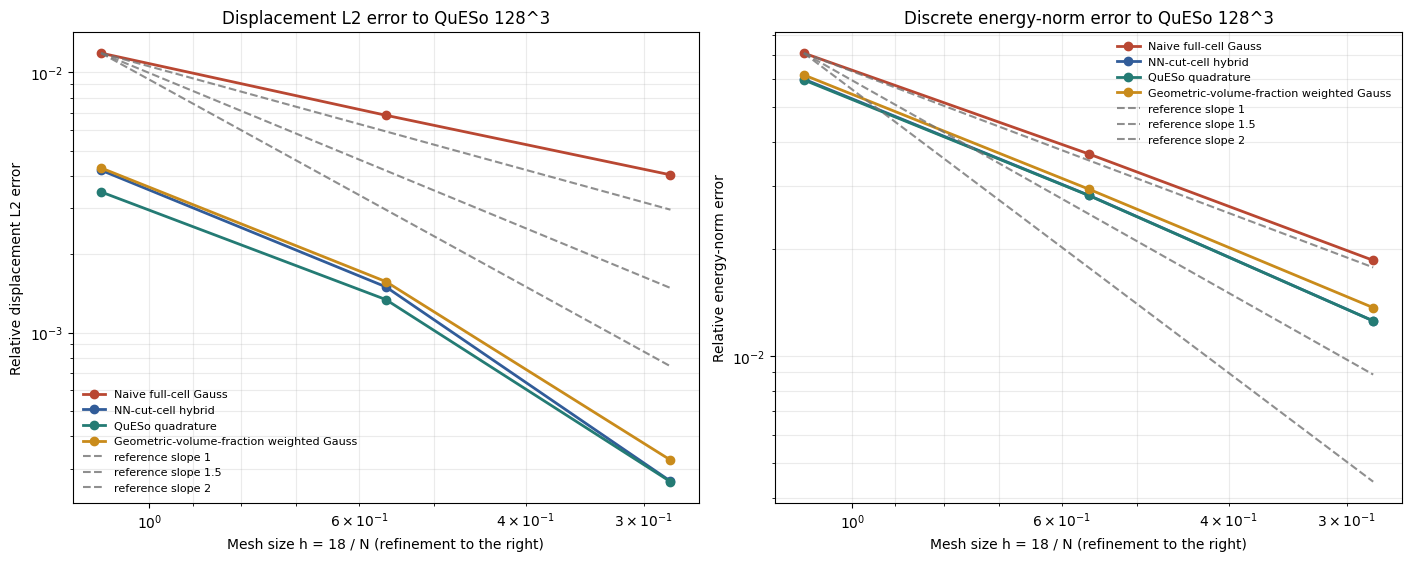

Validated common support volume: 1766.904541.
Reference energy norm: 43.401455.
Fit uses N=16, 32, 64.
Saved validated data to C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local\smooth_radial_foundation_sub9\four_framework_physical_volume_weighted_l2_and_energy_vs_queso_128.csv
Saved validated plot to C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local\smooth_radial_foundation_sub9\four_framework_fixed_reference_support_l2_and_energy_vs_queso_128.png


In [119]:
# Validated physical-domain displacement accuracy AND discrete energy-norm error
# to the selected QuESo reference.
# Run the archive and metric integrity audit immediately above this cell first.
#
# Energy norm added because per-cell Ke comparisons (previous audit) showed naive
# and weighted carry an O(1) relative stiffness-matrix error that does NOT shrink
# with h (median ~0.9-1.0 for naive, ~0.44-0.63 for weighted, all resolutions).
# By Strang's second lemma, energy-norm error directly inherits this consistency
# error; by Aubin-Nitsche duality, L2 displacement error is one order better and
# can hide it. e_energy^2 = d^T K_ref d, with d = u_h - u_ref (interpolated onto
# the reference grid) and K_ref QuESo's own assembled reference-resolution operator.
import matplotlib.pyplot as plt

required = (
    'archive_audit', 'plot_invalid_archives', 'plot_resolutions',
    'hanging_sphere_evaluator', 'ANALYSIS_DIR', 'ANALYSIS_OUTPUT_ROOT',
    'ANALYSIS_REFERENCE_RESOLUTION',
)
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Run the archive and metric integrity audit first; missing: ' + ', '.join(missing))
if not plot_invalid_archives.empty:
    raise RuntimeError(
        'Refusing to plot invalid convergence data. Generate the QuESo reference or repair the frameworks '
        'listed by the graph audit, then rerun the audit and this cell.'
    )

reference_field, reference_cells = hanging_sphere_evaluator.load_checkpoint(
    ANALYSIS_DIR, 'queso', ANALYSIS_REFERENCE_RESOLUTION,
)
reference_mask = hanging_sphere_evaluator.active_node_mask(
    reference_cells, ANALYSIS_REFERENCE_RESOLUTION,
)
reference_weights = hanging_sphere_evaluator.physical_nodal_weights(
    OUTPUT_DIR, reference_cells, ANALYSIS_REFERENCE_RESOLUTION,
)
reference_mask &= reference_weights > 0.0
reference_volume = float(reference_weights[reference_mask].sum())
if not reference_mask.any() or not np.isfinite(reference_volume) or reference_volume <= 0.0:
    raise RuntimeError('Reference support is empty or has non-positive physical volume.')

# --- Build QuESo's own reference-resolution operator, once, for the energy norm ---
phase(f'Building reference operator at {ANALYSIS_REFERENCE_RESOLUTION}^3 for energy-norm error')
(case_ref, full_ke_ref, strict_full_indices_ref, queso_cut_ke_ref, queso_cut_indices_ref, active_ref,
 shared_force_ref, fractions_ref, queso_full_ke_ref, queso_full_indices_ref) = build_hard_constraint_problem(
    ANALYSIS_REFERENCE_RESOLUTION
)
if not np.array_equal(active_ref.numpy(), reference_cells):
    raise AssertionError(
        'Rebuilt reference active-cell set does not match the archived QuESo reference checkpoint -- '
        'the geometry/cache used to build the operator differs from the one used to solve it.'
    )
foundation_ref, constrained_dofs_ref, support_metadata_ref = support_boundary_terms(
    case_ref, active_ref, queso_cut_indices_ref,
)
reference_operator = StructuredCompressedMatrixFreeElasticityOperator(
    full_ke_ref, strict_full_indices_ref, queso_cut_ke_ref, queso_cut_indices_ref,
    tuple(case_ref.grid.resolution), foundation_ref,
    element_batch_size=32768, slab_cells=1, constrained_dofs=constrained_dofs_ref,
)
reference_node_dof_mask = np.repeat(reference_mask, 3)


def discrete_energy_error(field_on_reference, reference_field, reference_operator, reference_node_dof_mask):
    difference = (field_on_reference - reference_field).reshape(-1).astype(np.float64)
    difference[~reference_node_dof_mask] = 0.0
    difference_tensor = torch.as_tensor(difference, dtype=reference_operator.dtype, device=reference_operator.device)
    k_difference = reference_operator.matvec(difference_tensor)
    energy_squared = float(torch.dot(difference_tensor, k_difference))
    return float(np.sqrt(max(energy_squared, 0.0)))


reference_energy_norm = discrete_energy_error(
    reference_field, np.zeros_like(reference_field), reference_operator, reference_node_dof_mask,
)
if not np.isfinite(reference_energy_norm) or reference_energy_norm <= 0.0:
    raise RuntimeError('Reference energy norm is non-positive or non-finite; cannot form a relative energy error.')

rows = []
for framework, framework_label in ALL_FRAMEWORKS.items():
    for resolution in plot_resolutions:
        field, active_cells = hanging_sphere_evaluator.load_checkpoint(ANALYSIS_DIR, framework, resolution)
        expected_cells, _ = load_archive_support('queso', resolution)
        if not np.array_equal(active_cells, expected_cells):
            raise AssertionError(f'{framework} {resolution}^3 no longer matches the audited QuESo support.')
        field_on_reference = hanging_sphere_evaluator.field_on_reference_grid(field)
        comparison_nodes, vector_error, component_error = hanging_sphere_evaluator.relative_errors(
            field_on_reference, reference_mask, reference_field, reference_weights,
        )
        absolute_energy_error = discrete_energy_error(
            field_on_reference, reference_field, reference_operator, reference_node_dof_mask,
        )
        rows.append({
            'framework': framework,
            'framework_label': framework_label,
            'reference_framework': 'queso',
            'reference_resolution': ANALYSIS_REFERENCE_RESOLUTION,
            'region': 'fixed_queso_reference_support',
            'resolution': resolution,
            'h': 18.0 / resolution,
            'comparison_nodes': comparison_nodes,
            'shared_support_volume': reference_volume,
            'relative_l2_error': vector_error,
            'relative_l2_error_x': component_error[0],
            'relative_l2_error_y': component_error[1],
            'relative_l2_error_z': component_error[2],
            'absolute_energy_error': absolute_energy_error,
            'relative_energy_error': absolute_energy_error / reference_energy_norm,
        })

validated_convergence_results = pd.DataFrame(rows).sort_values(['framework', 'resolution']).reset_index(drop=True)
validated_convergence_results['local_order'] = np.nan
validated_convergence_results['local_order_energy'] = np.nan
for _, curve in validated_convergence_results.groupby('framework', sort=False):
    errors = curve['relative_l2_error'].to_numpy()
    energy_errors = curve['relative_energy_error'].to_numpy()
    mesh_sizes = curve['h'].to_numpy()
    local_orders = np.log(errors[:-1] / errors[1:]) / np.log(mesh_sizes[:-1] / mesh_sizes[1:])
    local_orders_energy = np.log(energy_errors[:-1] / energy_errors[1:]) / np.log(mesh_sizes[:-1] / mesh_sizes[1:])
    validated_convergence_results.loc[curve.index[:-1], 'local_order'] = local_orders
    validated_convergence_results.loc[curve.index[:-1], 'local_order_energy'] = local_orders_energy

fit_resolutions = tuple(plot_resolutions)
fit_rows = []
for framework, curve in validated_convergence_results.groupby('framework', sort=False):
    fit_curve = curve[curve['resolution'].isin(fit_resolutions)].sort_values('resolution')
    if len(fit_curve) < 2:
        continue
    slope, intercept = np.polyfit(np.log(fit_curve['h']), np.log(fit_curve['relative_l2_error']), 1)
    prediction = slope * np.log(fit_curve['h']) + intercept
    total = np.sum((np.log(fit_curve['relative_l2_error']) - np.log(fit_curve['relative_l2_error'].mean())) ** 2)

    energy_slope, energy_intercept = np.polyfit(np.log(fit_curve['h']), np.log(fit_curve['relative_energy_error']), 1)
    energy_prediction = energy_slope * np.log(fit_curve['h']) + energy_intercept
    energy_total = np.sum((np.log(fit_curve['relative_energy_error']) - np.log(fit_curve['relative_energy_error'].mean())) ** 2)

    fit_rows.append({
        'framework': framework,
        'framework_label': fit_curve['framework_label'].iloc[0],
        'fit_resolutions': ', '.join(map(str, fit_resolutions)),
        'empirical_order_l2': slope,
        'r_squared_l2': np.nan if total == 0.0 else 1.0 - np.sum((np.log(fit_curve['relative_l2_error']) - prediction) ** 2) / total,
        'empirical_order_energy': energy_slope,
        'r_squared_energy': np.nan if energy_total == 0.0 else 1.0 - np.sum((np.log(fit_curve['relative_energy_error']) - energy_prediction) ** 2) / energy_total,
    })
fit_summary = pd.DataFrame(
    fit_rows,
    columns=('framework', 'framework_label', 'fit_resolutions', 'empirical_order_l2', 'r_squared_l2', 'empirical_order_energy', 'r_squared_energy'),
)
display(validated_convergence_results)
display(fit_summary)

results_path = ANALYSIS_DIR / f'four_framework_physical_volume_weighted_l2_and_energy_vs_queso_{ANALYSIS_REFERENCE_RESOLUTION}.csv'
validated_convergence_results.to_csv(results_path, index=False)
fit_summary.to_csv(results_path.with_name(results_path.stem + '_global_fits.csv'), index=False)

colors = {'naive': '#b94732', 'weighted': '#c98b1b', 'queso': '#247b74', 'nn': '#315c99'}
figure, (axis_l2, axis_energy) = plt.subplots(1, 2, figsize=(14.0, 5.5), constrained_layout=True)

for framework, curve in validated_convergence_results.groupby('framework', sort=False):
    curve = curve.sort_values('h', ascending=False)
    axis_l2.loglog(curve['h'], curve['relative_l2_error'], marker='o', linewidth=2, color=colors[framework], label=curve['framework_label'].iloc[0])
    axis_energy.loglog(curve['h'], curve['relative_energy_error'], marker='o', linewidth=2, color=colors[framework], label=curve['framework_label'].iloc[0])

reference_h = np.asarray(sorted(validated_convergence_results['h'].unique(), reverse=True))
anchor_h = validated_convergence_results['h'].max()
anchor_l2 = validated_convergence_results.loc[validated_convergence_results['h'].idxmax(), 'relative_l2_error']
anchor_energy = validated_convergence_results.loc[validated_convergence_results['h'].idxmax(), 'relative_energy_error']
for order in (1.0, 1.5, 2.0):
    axis_l2.loglog(reference_h, anchor_l2 * (reference_h / anchor_h) ** order, '--', color='0.45', alpha=0.8, label=f'reference slope {order:g}')
    axis_energy.loglog(reference_h, anchor_energy * (reference_h / anchor_h) ** order, '--', color='0.45', alpha=0.8, label=f'reference slope {order:g}')

for axis, title, ylabel in (
    (axis_l2, f'Displacement L2 error to QuESo {ANALYSIS_REFERENCE_RESOLUTION}^3', 'Relative displacement L2 error'),
    (axis_energy, f'Discrete energy-norm error to QuESo {ANALYSIS_REFERENCE_RESOLUTION}^3', 'Relative energy-norm error'),
):
    axis.invert_xaxis()
    axis.set(title=title, xlabel='Mesh size h = 18 / N (refinement to the right)', ylabel=ylabel)
    axis.grid(True, which='both', alpha=0.25)
    axis.legend(frameon=False, fontsize=8)

plot_path = results_path.with_name(f'four_framework_fixed_reference_support_l2_and_energy_vs_queso_{ANALYSIS_REFERENCE_RESOLUTION}.png')
figure.savefig(plot_path, dpi=180, bbox_inches='tight')
plt.show()

del case_ref, full_ke_ref, strict_full_indices_ref, queso_cut_ke_ref, queso_cut_indices_ref, active_ref
del shared_force_ref, fractions_ref, queso_full_ke_ref, queso_full_indices_ref, foundation_ref, reference_operator
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(f'Validated common support volume: {reference_volume:.6f}.')
print(f'Reference energy norm: {reference_energy_norm:.6f}.')
print(f'Fit uses N={", ".join(map(str, fit_resolutions))}.')
print(f'Saved validated data to {results_path}')
print(f'Saved validated plot to {plot_path}')

In [91]:
print(plot_invalid_archives)

Empty DataFrame
Columns: [resolution, framework, status, active_cells, matches_queso_support, only_framework_cells, only_queso_cells]
Index: []


In [92]:
print('SUPPORT_OUTPUT_DIR =', SUPPORT_OUTPUT_DIR)
print('ANALYSIS_DIR        =', ANALYSIS_DIR)
print('same directory?', SUPPORT_OUTPUT_DIR.resolve() == ANALYSIS_DIR.resolve())

SUPPORT_OUTPUT_DIR = C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local\smooth_radial_foundation_sub9
ANALYSIS_DIR        = C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_queso_inner_cells_local\smooth_radial_foundation_sub9
same directory? True


In [94]:
# Reuses the earlier per-cell audit pattern, on THIS problem's geometry, no dilution.
resolution_for_ke_audit = 64
case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions, queso_full_ke, queso_full_indices = build_hard_constraint_problem(resolution_for_ke_audit)

weighted_ke = full_ke.expand(len(cut_indices), -1, -1).clone() * fractions[:, None, None]
naive_ke = full_ke.expand(len(cut_indices), -1, -1).clone()

reference_norm = torch.linalg.matrix_norm(queso_cut_ke, ord='fro').clamp_min(torch.finfo(torch.float64).tiny)
weighted_rel_error = torch.linalg.matrix_norm(weighted_ke - queso_cut_ke, ord='fro') / reference_norm
naive_rel_error = torch.linalg.matrix_norm(naive_ke - queso_cut_ke, ord='fro') / reference_norm

print(f'naive vs queso Ke:    median={naive_rel_error.median():.4f}  max={naive_rel_error.max():.4f}')
print(f'weighted vs queso Ke: median={weighted_rel_error.median():.4f}  max={weighted_rel_error.max():.4f}')

Reusing cached physical sphere surface and QuESo artifacts in queso_matrix_free_64cubed.
[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.1223 seconds.
[CASE BUILD] QuESo settings write took 0.0010 seconds.
[CASE BUILD] Reusing 2,310,957 retained QuESo points from queso_all_points.npy.
[CASE BUILD] QuESo total took 0.0160 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.1413 seconds.
Independent subcell volume fractions: min=0.00106812; median=0.503906; mean=0.508727; max=1
naive vs queso Ke:    median=0.9939  max=345.8338
weighted vs queso Ke: median=0.4573  max=0.9174


In [95]:
ke_error_by_resolution = []
for resolution in (8, 16, 32, 64):
    case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions, queso_full_ke, queso_full_indices = build_hard_constraint_problem(resolution)
    weighted_ke = full_ke.expand(len(cut_indices), -1, -1).clone() * fractions[:, None, None]
    naive_ke = full_ke.expand(len(cut_indices), -1, -1).clone()
    reference_norm = torch.linalg.matrix_norm(queso_cut_ke, ord='fro').clamp_min(torch.finfo(torch.float64).tiny)
    weighted_rel = torch.linalg.matrix_norm(weighted_ke - queso_cut_ke, ord='fro') / reference_norm
    naive_rel = torch.linalg.matrix_norm(naive_ke - queso_cut_ke, ord='fro') / reference_norm
    ke_error_by_resolution.append({
        'resolution': resolution, 'h': 18.0 / resolution, 'cut_cells': len(cut_indices),
        'naive_median': float(naive_rel.median()), 'naive_max': float(naive_rel.max()),
        'weighted_median': float(weighted_rel.median()), 'weighted_max': float(weighted_rel.max()),
    })
    del case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions, queso_full_ke, queso_full_indices
    gc.collect()

ke_error_df = pd.DataFrame(ke_error_by_resolution)
display(ke_error_df)
for column in ('naive_median', 'weighted_median'):
    errors = ke_error_df[column].to_numpy()
    mesh_sizes = ke_error_df['h'].to_numpy()
    orders = np.log(errors[:-1] / errors[1:]) / np.log(mesh_sizes[:-1] / mesh_sizes[1:])
    print(f'{column} local orders: {orders}')

Reusing cached physical sphere surface and QuESo artifacts in queso_matrix_free_8cubed.
[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.1414 seconds.
[CASE BUILD] QuESo settings write took 0.0009 seconds.
[CASE BUILD] Reusing 7,560 retained QuESo points from queso_all_points.npy.
[CASE BUILD] QuESo total took 0.0193 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.1631 seconds.
Independent subcell volume fractions: min=0.0234375; median=0.232422; mean=0.377188; max=0.998047
Reusing cached physical sphere surface and QuESo artifacts in queso_matrix_free_16cubed.
[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[

,resolution,h,cut_cells,naive_median,naive_max,weighted_median,weighted_max
0,8,2.25000,200,2.501411,19.039888,0.628366,0.831533
1,16,1.12500,800,1.160727,238.782869,0.489326,0.901549
2,32,0.56250,3248,0.901212,110.752332,0.436510,0.922510
3,64,0.28125,12728,0.993851,345.833811,0.457318,0.917419


naive_median local orders: [ 1.1077129   0.3650913  -0.14116291]
weighted_median local orders: [ 0.36080982  0.16478168 -0.06718384]


In [ ]:
# 8^3 trimmed-cell stiffness audit, including QuESo.
# The global operator receives (full_ke, full_indices) separately from
# (cut_matrices, cut_indices): full cells are Gauss-only by construction.
required = ('PLANAR_CAP_OUTPUT_DIR', 'build_hard_constraint_problem', 'hard_constraint_cut_matrices',
            'prepare_nn_inputs', 'compute_nn_cutcell_stiffness', 'load_nn_engine', 'NN_CHECKPOINT')
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Run the setup and planar-cap cells first; missing: ' + ', '.join(missing))

MATRIX_AUDIT_RESOLUTION = 8
MATRIX_AUDIT_PATH = PLANAR_CAP_OUTPUT_DIR / f'trimmed_cell_matrix_audit_{MATRIX_AUDIT_RESOLUTION}cubed.csv'
case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions = build_hard_constraint_problem(
    MATRIX_AUDIT_RESOLUTION
)
if torch.isin(full_indices, cut_indices).any():
    raise AssertionError('Interior and trimmed cell sets overlap.')
if not torch.equal(active, torch.sort(torch.cat((full_indices, cut_indices))).values):
    raise AssertionError('Active cells are not exactly the union of interior and trimmed cells.')

nn_engine = load_nn_engine(checkpoint_path=NN_CHECKPOINT, device=SOLVE_DEVICE, dtype='float32')
try:
    d_cut, nu_cut, h_ref = prepare_nn_inputs(
        grid=case.grid, volume=case.volume, partial_indices=cut_indices,
        material=case.material, poly_order=case.poly_order,
    )
    nn_raw_matrices, nn_indices = compute_nn_cutcell_stiffness(
        d_cut=d_cut, nu_cut=nu_cut, nn_engine=nn_engine, material=case.material,
        partial_indices=cut_indices, h_ref=h_ref,
    )
    if not torch.equal(nn_indices, cut_indices):
        raise AssertionError('NN inference returned IDs other than the trimmed-cell IDs.')
    cut_matrices = {
        'naive': hard_constraint_cut_matrices('naive', case, full_ke, queso_cut_ke, cut_indices, fractions),
        'weighted': hard_constraint_cut_matrices('weighted', case, full_ke, queso_cut_ke, cut_indices, fractions),
        'queso': hard_constraint_cut_matrices('queso', case, full_ke, queso_cut_ke, cut_indices, fractions),
        'nn': hard_constraint_cut_matrices('nn', case, full_ke, queso_cut_ke, cut_indices, fractions, nn_engine),
    }
finally:
    del nn_engine

nn_expected = torch.stack(nn_raw_matrices).to(dtype=torch.float64)
nn_repeat_difference = torch.linalg.matrix_norm(cut_matrices['nn'].to(torch.float64) - nn_expected, ord='fro')
nn_repeat_relative = float((nn_repeat_difference / torch.linalg.matrix_norm(nn_expected, ord='fro').clamp_min(torch.finfo(torch.float64).tiny)).max())
if not np.isfinite(nn_repeat_relative):
    raise AssertionError('NN repeat-inference check produced a non-finite matrix difference.')

queso_norm = torch.linalg.matrix_norm(cut_matrices['queso'].to(torch.float64), ord='fro').clamp_min(torch.finfo(torch.float64).tiny)
summary_rows = []
for framework, matrices in cut_matrices.items():
    matrices = matrices.to(torch.float64)
    difference = matrices - cut_matrices['queso'].to(torch.float64)
    relative_error = torch.linalg.matrix_norm(difference, ord='fro') / queso_norm
    cosine = (matrices * cut_matrices['queso'].to(torch.float64)).sum((1, 2))
    cosine /= torch.linalg.matrix_norm(matrices, ord='fro').clamp_min(torch.finfo(torch.float64).tiny) * queso_norm
    summary_rows.append({
        'framework': framework,
        'trimmed_cells': len(cut_indices),
        'median_relative_frobenius_error_vs_queso': float(relative_error.median()),
        'p95_relative_frobenius_error_vs_queso': float(torch.quantile(relative_error, 0.95)),
        'max_relative_frobenius_error_vs_queso': float(relative_error.max()),
        'median_cosine_similarity_to_queso': float(cosine.median()),
        'minimum_cosine_similarity_to_queso': float(cosine.min()),
    })

matrix_audit = pd.DataFrame(summary_rows).sort_values('framework')
matrix_audit.to_csv(MATRIX_AUDIT_PATH, index=False)
display(matrix_audit)
display(pd.DataFrame([{
    'resolution': MATRIX_AUDIT_RESOLUTION,
    'full_interior_cells': len(full_indices),
    'trimmed_cells': len(cut_indices),
    'active_cells': len(active),
    'full_cells_use_shared_gauss_matrix': True,
    'nn_ids_equal_trimmed_ids': True,
    'nn_repeat_inference_max_relative_difference': nn_repeat_relative,
}]))

del nn_raw_matrices, nn_indices, nn_expected, cut_matrices, case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f'Saved trimmed-cell similarity audit to {MATRIX_AUDIT_PATH}')

[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.0103 seconds.
[CASE BUILD] QuESo settings write took 0.0010 seconds.
[CASE BUILD] Reusing 5,387 retained QuESo points from queso_cut_points.npy.
[CASE BUILD] QuESo total took 0.0027 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.0158 seconds.
Cut-cell volume fractions: min=0.0241014; median=0.228625; mean=0.374025; max=0.997869
8


,framework,trimmed_cells,median_relative_frobenius_error_vs_queso,p95_relative_frobenius_error_vs_queso,max_relative_frobenius_error_vs_queso,median_cosine_similarity_to_queso,minimum_cosine_similarity_to_queso
0,naive,200,2.528862,19.646551,19.646551,0.777751,0.556926
3,nn,200,0.189321,0.448740,0.449967,0.997873,0.993006
2,queso,200,0.000000,0.000000,0.000000,1.000000,1.000000
1,weighted,200,0.629840,0.833815,0.833815,0.777751,0.556926


,resolution,full_interior_cells,trimmed_cells,active_cells,full_cells_use_shared_gauss_matrix,nn_ids_equal_trimmed_ids,nn_repeat_inference_max_relative_difference
0,8,80,200,280,True,True,6.208755e-07


Saved trimmed-cell similarity audit to C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence\planar_cap_plane_hard_constraints\trimmed_cell_matrix_audit_8cubed.csv


In [ ]:
# Why distinct trimmed matrices can still yield similar global displacement-error curves.
# Compare the stored 8^3 fields directly and partition each field's elastic
# energy into identical full-cell and framework-specific trimmed-cell sets.
required = ('build_hard_constraint_problem', 'hard_constraint_cut_matrices', 'load_nn_engine', 'NN_CHECKPOINT')
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError('Run the setup and planar-cap cells first; missing: ' + ', '.join(missing))

resolution = 8
case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions = build_hard_constraint_problem(resolution)
solutions = {}
for framework in ('naive', 'weighted', 'queso', 'nn'):
    path = planar_cap_solution_path(framework, resolution)
    if not path.is_file():
        raise FileNotFoundError(f'Missing {framework} {resolution}^3 checkpoint: {path}')
    solutions[framework] = torch.from_numpy(np.load(path)['u_nodes']).to(torch.float64)

nn_engine = load_nn_engine(checkpoint_path=NN_CHECKPOINT, device=SOLVE_DEVICE, dtype='float32')
try:
    cut_matrices = {
        framework: hard_constraint_cut_matrices(
            framework, case, full_ke, queso_cut_ke, cut_indices, fractions, nn_engine if framework == 'nn' else None,
        ).to(torch.float64)
        for framework in solutions
    }
finally:
    del nn_engine

full_nodes = active_element_nodes(full_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu')
cut_nodes = active_element_nodes(cut_indices, case.grid.resolution, poly_order=case.poly_order, device='cpu')
energy_rows = []
for framework, displacement in solutions.items():
    full_local_u = displacement[full_nodes].reshape(len(full_indices), 24)
    cut_local_u = displacement[cut_nodes].reshape(len(cut_indices), 24)
    full_energy = 0.5 * torch.einsum('bi,ij,bj->', full_local_u, full_ke.to(torch.float64), full_local_u)
    cut_energy = 0.5 * torch.einsum('bi,bij,bj->', cut_local_u, cut_matrices[framework], cut_local_u)
    total_energy = full_energy + cut_energy
    energy_rows.append({
        'framework': framework,
        'full_cell_strain_energy_fraction': float(full_energy / total_energy),
        'trimmed_cell_strain_energy_fraction': float(cut_energy / total_energy),
    })

pairwise_rows = []
for framework, displacement in solutions.items():
    difference = displacement - solutions['queso']
    pairwise_rows.append({
        'framework': framework,
        'relative_nodal_l2_difference_to_queso_at_8cubed': float(
            torch.linalg.vector_norm(difference) / torch.linalg.vector_norm(solutions['queso'])
        ),
        'maximum_nodal_displacement_difference_to_queso_at_8cubed': float(
            torch.linalg.vector_norm(difference, dim=1).max()
        ),
    })

display(pd.DataFrame(pairwise_rows).sort_values('framework'))
display(pd.DataFrame(energy_rows).sort_values('framework'))
print('At 8^3, the direct field differences and trimmed-cell energy shares are substantial even when convergence-error curves look similar.')

del solutions, cut_matrices, case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.0169 seconds.
[CASE BUILD] QuESo settings write took 0.0013 seconds.
[CASE BUILD] Reusing 5,387 retained QuESo points from queso_cut_points.npy.
[CASE BUILD] QuESo total took 0.0025 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.0230 seconds.
Cut-cell volume fractions: min=0.0241014; median=0.228625; mean=0.374025; max=0.997869


C:\Users\z0058p1u\Documents\code\clean_simulation\nn_runtime.py:44: RuntimeWarning: Skipping torch.set_num_interop_threads after runtime init (Error: cannot set number of interop threads after parallel work has started or set_num_interop_threads called).
  return FastCutCellInference.from_checkpoint(ckpt, options=options)


8


C:\Users\z0058p1u\Documents\code\clean_simulation\internal_nn_runtime\cutcell_ml\model.py:920: TracerWarning: Iterating over a tensor might cause the trace to be incorrect. Passing a tensor of different shape won't change the number of iterations executed (and might lead to errors or silently give incorrect results).
  rows, cols = torch.triu_indices(


,framework,relative_nodal_l2_difference_to_queso_at_8cubed,maximum_nodal_displacement_difference_to_queso_at_8cubed
0,naive,0.488209,0.002879
3,nn,0.101937,0.002214
2,queso,0.000000,0.000000
1,weighted,2.346118,0.012846


,framework,full_cell_strain_energy_fraction,trimmed_cell_strain_energy_fraction
0,naive,0.403994,0.596006
3,nn,0.499984,0.500016
2,queso,0.489092,0.510908
1,weighted,0.194988,0.805012


At 8^3, the direct field differences and trimmed-cell energy shares are substantial even when convergence-error curves look similar.


In [ ]:
# Compare cut-cell matrices at identical structured-cell coordinates against QuESo.
# This isolates the cut-cell approximation from the global assembly and solve.
LOCAL_MATRIX_AUDIT_RESOLUTION = 16
LOCAL_MATRIX_AUDIT_PATH = PLANAR_CAP_OUTPUT_DIR / f"four_framework_local_matrix_audit_{LOCAL_MATRIX_AUDIT_RESOLUTION}cubed.csv"

required_local_matrix_audit_helpers = (
    "build_hard_constraint_problem",
    "hard_constraint_cut_matrices",
)
missing_local_matrix_audit_helpers = [name for name in required_local_matrix_audit_helpers if name not in globals()]
if missing_local_matrix_audit_helpers:
    raise RuntimeError(
        "Run the planar-cap problem setup cells first; missing: "
        + ", ".join(missing_local_matrix_audit_helpers)
    )

case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions = build_hard_constraint_problem(
    LOCAL_MATRIX_AUDIT_RESOLUTION
)
nn_engine = load_nn_engine(
    checkpoint_path=NN_CHECKPOINT,
    device="cuda" if torch.cuda.is_available() else "cpu",
    dtype="float32",
)
cut_matrices_by_framework = {
    "queso": queso_cut_ke.to(dtype=torch.float64, device="cpu"),
    "naive": hard_constraint_cut_matrices(
        "naive", case, full_ke, queso_cut_ke, cut_indices, fractions
    ).to(dtype=torch.float64, device="cpu"),
    "weighted": hard_constraint_cut_matrices(
        "weighted", case, full_ke, queso_cut_ke, cut_indices, fractions
    ).to(dtype=torch.float64, device="cpu"),
    "nn": hard_constraint_cut_matrices(
        "nn", case, full_ke, queso_cut_ke, cut_indices, fractions, nn_engine
    ).to(dtype=torch.float64, device="cpu"),
}
del nn_engine
if torch.cuda.is_available():
    torch.cuda.empty_cache()

reference_norm = torch.linalg.matrix_norm(cut_matrices_by_framework["queso"], ord="fro")
reference_norm = reference_norm.clamp_min(torch.finfo(torch.float64).tiny)
local_matrix_rows = []
for framework in ("naive", "weighted", "nn"):
    difference = cut_matrices_by_framework[framework] - cut_matrices_by_framework["queso"]
    relative_frobenius_error = torch.linalg.matrix_norm(difference, ord="fro") / reference_norm
    symmetry_defect = torch.linalg.matrix_norm(
        cut_matrices_by_framework[framework] - cut_matrices_by_framework[framework].transpose(1, 2),
        ord="fro",
    ) / torch.linalg.matrix_norm(cut_matrices_by_framework[framework], ord="fro").clamp_min(
        torch.finfo(torch.float64).tiny
    )
    for index, cell_id in enumerate(cut_indices.cpu().numpy()):
        local_matrix_rows.append({
            "resolution": LOCAL_MATRIX_AUDIT_RESOLUTION,
            "cell_id": int(cell_id),
            "framework": framework,
            "physical_volume_fraction": float(fractions[index]),
            "relative_frobenius_error_vs_queso": float(relative_frobenius_error[index]),
            "max_absolute_entry_error_vs_queso": float(difference[index].abs().max()),
            "relative_symmetry_defect": float(symmetry_defect[index]),
        })

local_matrix_audit = pd.DataFrame(local_matrix_rows)
local_matrix_audit.to_csv(LOCAL_MATRIX_AUDIT_PATH, index=False)
local_matrix_summary = (
    local_matrix_audit.groupby("framework", sort=False)
    .agg(
        cut_cells=("cell_id", "size"),
        median_relative_frobenius_error=("relative_frobenius_error_vs_queso", "median"),
        p95_relative_frobenius_error=("relative_frobenius_error_vs_queso", lambda values: values.quantile(0.95)),
        max_relative_frobenius_error=("relative_frobenius_error_vs_queso", "max"),
        median_relative_symmetry_defect=("relative_symmetry_defect", "median"),
        max_relative_symmetry_defect=("relative_symmetry_defect", "max"),
    )
    .reset_index()
)
print(f"Local matrix audit at {LOCAL_MATRIX_AUDIT_RESOLUTION}^3 on {len(cut_indices):,} identical cut-cell coordinates")
display(local_matrix_summary)

for name in tuple(cut_matrices_by_framework):
    del cut_matrices_by_framework[name]
del case, full_ke, full_indices, queso_cut_ke, cut_indices, active, force, fractions
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f"Saved per-cell matrix errors to {LOCAL_MATRIX_AUDIT_PATH}")

[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.0281 seconds.
[CASE BUILD] QuESo settings write took 0.0008 seconds.
[CASE BUILD] Reusing 21,469 retained QuESo points from queso_cut_points.npy.
[CASE BUILD] QuESo total took 0.0120 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.0433 seconds.
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 2/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 4/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 6/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 8/16 [0.0s]
[HIGH RESOLUTION] exact sphere full-cell classification: x slab 10/16 [0.0s]
[

: 

In [38]:
# Materialized global-K timing for every framework and configured resolution.
# This uses SciPy CSR deliberately: unlike the matrix-free solver operator, it builds an explicit global K.
import json
import scipy.sparse as sp
from clean_simulation.internal_fem_kernel.runtime.assembly_ops import assemble_stiffness_base

required_global_k = (
    'build_hard_constraint_problem', 'hard_constraint_cut_matrices', 'framework_support',
    'support_boundary_terms', 'load_nn_engine', 'NN_CHECKPOINT',
)
missing_global_k = [name for name in required_global_k if name not in globals()]
if missing_global_k:
    raise RuntimeError('Run the setup and support cells first; missing: ' + ', '.join(missing_global_k))

GLOBAL_K_RESOLUTIONS = tuple(int(value) for value in os.environ.get(
    'HANGING_SPHERE_GLOBAL_K_RESOLUTIONS', ','.join(map(str, RESOLUTION_SCHEDULE)),
).split(','))
GLOBAL_K_OUTPUT_DIR = SUPPORT_OUTPUT_DIR / 'global_k_timings'
GLOBAL_K_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
GLOBAL_K_CSV = GLOBAL_K_OUTPUT_DIR / 'four_framework_global_k_timings.csv'
GLOBAL_K_JSON = GLOBAL_K_OUTPUT_DIR / 'four_framework_global_k_timings.json'

def seconds_since(started):
    return time.perf_counter() - started

def save_global_k_timings(rows):
    table = pd.DataFrame(rows)
    table.to_csv(GLOBAL_K_CSV, index=False)
    GLOBAL_K_JSON.write_text(json.dumps(rows, indent=2), encoding='utf-8')
    return table

timing_rows = []
for resolution in GLOBAL_K_RESOLUTIONS:
    shared_started = time.perf_counter()
    case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, _, fractions = build_hard_constraint_problem(resolution)
    problem_preparation_seconds = seconds_since(shared_started)

    support_started = time.perf_counter()
    foundation, constrained_dofs, support_metadata = support_boundary_terms(case, active, queso_cut_indices)
    support_preparation_seconds = seconds_since(support_started)

    nn_engine = None
    nn_engine_load_seconds = 0.0
    try:
        for framework in ALL_FRAMEWORKS:
            row = {
                'resolution': resolution,
                'framework': framework,
                'support_mode': SUPPORT_MODE,
                'status': 'completed',
                'problem_preparation_seconds': problem_preparation_seconds,
                'support_preparation_seconds': support_preparation_seconds,
                'nn_engine_load_seconds': 0.0,
                'cut_matrix_preparation_seconds': np.nan,
                'global_matrix_input_preparation_seconds': np.nan,
                'global_k_csr_assembly_seconds': np.nan,
                'support_incorporation_seconds': np.nan,
                'total_framework_seconds': np.nan,
                'full_cells': len(strict_full_indices),
                'cut_cells': len(queso_cut_indices),
                'active_cells': len(active),
                'global_dofs': 3 * (resolution + 1) ** 3,
                'global_k_nnz': np.nan,
                'global_k_bytes': np.nan,
            }
            framework_started = time.perf_counter()
            try:
                if framework == 'nn' and nn_engine is None:
                    load_started = time.perf_counter()
                    nn_engine = load_nn_engine(checkpoint_path=NN_CHECKPOINT, device=SOLVE_DEVICE, dtype='float32')
                    nn_engine_load_seconds = seconds_since(load_started)
                row['nn_engine_load_seconds'] = nn_engine_load_seconds if framework == 'nn' else 0.0

                cut_started = time.perf_counter()
                full_indices, cut_indices, active_indices = framework_support(
                    framework, case, strict_full_indices, queso_cut_indices,
                )
                cut_matrices = hard_constraint_cut_matrices(
                    framework, case, full_ke, queso_cut_ke, cut_indices, fractions,
                    nn_engine if framework == 'nn' else None,
                ).to(dtype=torch.float64, device='cpu')
                row['cut_matrix_preparation_seconds'] = seconds_since(cut_started)

                input_started = time.perf_counter()
                full_matrices = full_ke.to(dtype=torch.float64, device='cpu').expand(len(full_indices), -1, -1)
                element_matrices = torch.cat((full_matrices, cut_matrices), dim=0).contiguous()
                assembly_indices = torch.cat((full_indices, cut_indices)).to(dtype=torch.int64, device='cpu')
                row['global_matrix_input_preparation_seconds'] = seconds_since(input_started)

                assembly_started = time.perf_counter()
                global_k = assemble_stiffness_base(
                    ke_list=element_matrices, active_indices=assembly_indices, grid=case.grid,
                    poly_order=case.poly_order, device='cpu', sparse_backend='scipy',
                )
                row['global_k_csr_assembly_seconds'] = seconds_since(assembly_started)

                support_started = time.perf_counter()
                if foundation is not None:
                    foundation = foundation.coalesce().cpu()
                    foundation_csr = sp.coo_matrix(
                        (foundation.values().numpy(), foundation.indices().numpy()),
                        shape=foundation.shape,
                    ).tocsr()
                    global_k = (global_k + foundation_csr).tocsr()
                elif constrained_dofs is not None:
                    constrained = constrained_dofs.cpu().numpy()
                    free = np.ones(global_k.shape[0], dtype=np.float64)
                    free[constrained] = 0.0
                    global_k = sp.diags(free, format='csr') @ global_k
                    global_k = global_k + sp.csr_matrix(
                        (np.ones(len(constrained)), (constrained, constrained)), shape=global_k.shape,
                    )
                row['support_incorporation_seconds'] = seconds_since(support_started)
                row['global_k_nnz'] = int(global_k.nnz)
                row['global_k_bytes'] = int(global_k.data.nbytes + global_k.indices.nbytes + global_k.indptr.nbytes)
            except Exception as error:
                row['status'] = f'failed: {type(error).__name__}: {error}'
            finally:
                row['total_framework_seconds'] = seconds_since(framework_started)
                timing_rows.append(row)
                save_global_k_timings(timing_rows)
                print(f"{resolution}^3 {framework}: {row['status']} in {row['total_framework_seconds']:.2f}s", flush=True)
                for name in ('cut_matrices', 'full_matrices', 'element_matrices', 'assembly_indices', 'global_k'):
                    if name in locals():
                        del globals()[name]
                gc.collect()
    finally:
        del nn_engine, case, full_ke, strict_full_indices, queso_cut_ke, queso_cut_indices, active, fractions, foundation
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

global_k_timing_results = save_global_k_timings(timing_rows)
display(global_k_timing_results)
print(f'Saved incremental timings to {GLOBAL_K_CSV} and {GLOBAL_K_JSON}')

Reusing cached physical sphere surface and QuESo artifacts in queso_matrix_free_8cubed.
[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.2521 seconds.
[CASE BUILD] QuESo settings write took 0.0023 seconds.
[CASE BUILD] Reusing 5,400 retained QuESo points from queso_cut_points.npy.
[CASE BUILD] QuESo total took 0.0200 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.2761 seconds.
Independent subcell volume fractions: min=0.0234375; median=0.232422; mean=0.377188; max=0.998047
8^3 naive: completed in 0.03s
8^3 weighted: completed in 0.02s
8^3 queso: completed in 0.01s


C:\Users\z0058p1u\Documents\code\clean_simulation\nn_runtime.py:44: RuntimeWarning: Skipping torch.set_num_interop_threads after runtime init (Error: cannot set number of interop threads after parallel work has started or set_num_interop_threads called).
  return FastCutCellInference.from_checkpoint(ckpt, options=options)


8


C:\Users\z0058p1u\Documents\code\clean_simulation\internal_nn_runtime\cutcell_ml\model.py:920: TracerWarning: Iterating over a tensor might cause the trace to be incorrect. Passing a tensor of different shape won't change the number of iterations executed (and might lead to errors or silently give incorrect results).
  rows, cols = torch.triu_indices(


8^3 nn: completed in 8.46s
Reusing cached physical sphere surface and QuESo artifacts in queso_matrix_free_16cubed.
[CASE BUILD] Configuring legacy imports and loading libraries...
[CASE BUILD] Imports took 0.0000 seconds.
[CASE BUILD] Geometry + mesh setup took 0.0114 seconds.
[CASE BUILD] QuESo settings write took 0.0011 seconds.
[CASE BUILD] Reusing 21,469 retained QuESo points from queso_cut_points.npy.
[CASE BUILD] QuESo total took 0.0148 seconds.
[CASE BUILD] QuESo Run() took 0.0000 seconds.
[CASE BUILD] QuESo IP extraction took 0.0000 seconds.
[CASE BUILD] QuESo inside/trimmed IP extraction: 0.0000s / 0.0000s.
[CASE BUILD] QuESo weight filtering took 0.0000 seconds.
[CASE BUILD] Total case build time: 0.0293 seconds.
Independent subcell volume fractions: min=0.00195312; median=0.453125; mean=0.471172; max=1
16^3 naive: completed in 0.04s
16^3 weighted: completed in 0.04s
16^3 queso: completed in 0.04s
8


...

8


C:\Users\z0058p1u\Documents\code\clean_simulation\internal_nn_runtime\cutcell_ml\model.py:920: TracerWarning: Iterating over a tensor might cause the trace to be incorrect. Passing a tensor of different shape won't change the number of iterations executed (and might lead to errors or silently give incorrect results).
  rows, cols = torch.triu_indices(


256^3 nn: failed: MemoryError: Unable to allocate 11.1 GiB for an array with shape (2978072064,) and data type int32 in 497.24s


,resolution,framework,support_mode,status,problem_preparation_seconds,support_preparation_seconds,nn_engine_load_seconds,cut_matrix_preparation_seconds,global_matrix_input_preparation_seconds,global_k_csr_assembly_seconds,support_incorporation_seconds,total_framework_seconds,full_cells,cut_cells,active_cells,global_dofs,global_k_nnz,global_k_bytes
0,8,naive,planar_cap,completed,0.806154,0.005472,0.000000,0.001936,0.000190,0.015065,0.014013,0.031220,80,200,280,2187,65976.0,8.004640e+05
1,8,weighted,planar_cap,completed,0.806154,0.005472,0.000000,0.000979,0.000250,0.007644,0.006629,0.015512,80,200,280,2187,71060.0,8.614720e+05
2,8,queso,planar_cap,completed,0.806154,0.005472,0.000000,0.000117,0.000194,0.006903,0.003834,0.011056,80,200,280,2187,72635.0,8.803720e+05
3,8,nn,planar_cap,completed,0.806154,0.005472,6.797691,1.655735,0.000179,0.006215,0.001215,8.461047,80,200,280,2187,72653.0,8.805880e+05
4,16,naive,planar_cap,completed,0.149335,0.003928,0.000000,0.001591,0.000855,0.033282,0.006296,0.042037,864,800,1664,14739,395432.0,4.804144e+06
5,16,weighted,planar_cap,completed,0.149335,0.003928,0.000000,0.003195,0.003047,0.029507,0.005686,0.041446,864,800,1664,14739,410643.0,4.986676e+06
6,16,queso,planar_cap,completed,0.149335,0.003928,0.000000,0.000162,0.001805,0.030534,0.006299,0.038807,864,800,1664,14739,413318.0,5.018776e+06
7,16,nn,planar_cap,completed,0.149335,0.003928,5.133975,0.470266,0.000846,0.035495,0.006722,5.647324,864,800,1664,14739,413383.0,5.019556e+06
8,32,naive,planar_cap,completed,0.418777,0.008103,0.000000,0.004597,0.008566,0.343769,0.038331,0.395287,8264,3248,11512,107811,2666071.0,3.242410e+07
9,32,weighted,planar_cap,completed,0.418777,0.008103,0.000000,0.007747,0.004645,0.197750,0.043825,0.253983,8264,3248,11512,107811,2734414.0,3.324422e+07


Saved incremental timings to C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_physical_fixed_support_local\planar_cap_plane_hard_constraints\global_k_timings\four_framework_global_k_timings.csv and C:\Users\z0058p1u\Documents\code\clean_simulation\outputs\sphere_displacement_convergence_physical_fixed_support_local\planar_cap_plane_hard_constraints\global_k_timings\four_framework_global_k_timings.json


In [ ]:
from clean_simulation.internal_nn_runtime.cutcell_bridge import output_to_k24_batch

In [ ]:
# Fresh, end-to-end K-construction timings for all four frameworks.
# Every resolution starts from an empty work directory: no saved geometry,
# QuESo points, stiffness matrices, or earlier timing table is reused.

import shutil
from clean_simulation.internal_nn_runtime.cutcell_bridge import (
    compute_cell_node_sdf_csc,
    output_to_k24_batch,
)

TIMING_RESOLUTIONS = (32, 64, 128)
TIMING_FRAMEWORKS = ('naive', 'weighted', 'queso', 'nn')
TIMING_CSV = OUTPUT_DIR / 'framework_isolated_K_timing_32_64_128cubed.csv'
NN_NARROW_BAND_TRI_CHUNK = 128

if not (torch.cuda.is_available() and torch.cuda.device_count() > 0):
    raise RuntimeError('Select a CUDA-backed notebook kernel before running this cell.')

TIMING_CSV.unlink(missing_ok=True)


def _sync_now():
    torch.cuda.synchronize()
    return time.perf_counter()


def _elapsed_since(started):
    return _sync_now() - started


def _full_cell_gauss_matrix(case, full_indices):
    full_seed = torch.zeros(int(np.prod(case.grid.resolution)), dtype=torch.bool)
    full_seed[full_indices[0]] = True
    return StiffnessAssembly.compute_inside_element_matrices(
        grid=case.grid,
        material=case.material,
        inside=full_seed,
        order=case.g_order,
        device='cpu',
        poly_order=case.poly_order,
    )[0][0]


def _build_fresh_support(resolution, work_dir):
    shutil.rmtree(work_dir, ignore_errors=True)
    work_dir.mkdir(parents=True, exist_ok=False)
    overrides = {
        **SPHERE_OVERRIDES,
        'grid': {**SPHERE_OVERRIDES['grid'], 'resolution': [resolution] * 3},
    }
    case = build_case_from_stl(
        stl_path=ensure_physical_sphere_stl(work_dir),
        overrides=overrides,
        workspace_root=root,
        work_dir=work_dir,
        queso_python_path=queso_python_path,
        queso_basis_order=2,
        cut_cells_only=True,
        integration_points_npy_path=work_dir / 'queso_cut_points.npy',
        bounds_padding=0.0,
        device='cpu',
    )
    cut_indices = torch.unique(point_cell_indices_and_weights(case)[0], sorted=True)
    full_indices = strict_sphere_full_cells(case)
    full_indices = full_indices[~torch.isin(full_indices, cut_indices)]
    if not len(full_indices) or not len(cut_indices):
        raise RuntimeError('Fresh support generation produced no full or no cut cells.')
    return case, full_indices, cut_indices


def _prepare_nn_narrow_band_inputs(case, queso_cut_indices, device):
    """Create NN features from one CSC pass over QuESo's fresh cut-cell IDs."""
    h_ref = float(case.grid.dx)
    d_raw = compute_cell_node_sdf_csc(
        grid=case.grid,
        volume=case.volume,
        cell_indices=queso_cut_indices,
        poly_order=case.poly_order,
        device=device,
        band_cells=3,
        tri_chunk=NN_NARROW_BAND_TRI_CHUNK,
    )
    d_normalized = -d_raw / (2.0 * np.sqrt(3.0) * h_ref) + 0.5
    nu_cut = torch.full((len(queso_cut_indices),), float(case.material.nu), dtype=torch.float64)
    return d_normalized, nu_cut, h_ref


def _operator_assembly(full_ke, full_indices, cut_matrices, cut_indices, case):
    started = _sync_now()
    operator = StructuredCompressedMatrixFreeElasticityOperator(
        full_ke,
        full_indices,
        cut_matrices,
        cut_indices,
        tuple(case.grid.resolution),
        None,
        element_batch_size=32768,
        slab_cells=1,
        constrained_dofs=None,
    )
    return operator, _elapsed_since(started)


print(f'Fresh timing run: {", ".join(f"{resolution}^3" for resolution in TIMING_RESOLUTIONS)}')
print(f'Frameworks: {", ".join(TIMING_FRAMEWORKS)}; CUDA device: {torch.cuda.get_device_name()}')

# Engine loading and warmup are deliberately excluded: NN timing consists only
# of QuESo-selected narrow-band input preparation, GPU inference, and assembly.
nn_engine = load_nn_engine(checkpoint_path=NN_CHECKPOINT, device='cuda', dtype='float32')
timing_rows = []

try:
    for resolution in TIMING_RESOLUTIONS:
        work_dir = OUTPUT_DIR / f'fresh_k_timing_{resolution}cubed'
        support_started = _sync_now()
        case, full_indices, cut_indices = _build_fresh_support(resolution, work_dir)
        queso_native_quadrature_seconds = _elapsed_since(support_started)
        print(
            f'\nN={resolution}^3 fresh QuESo quadrature/IP generation: '
            f'{queso_native_quadrature_seconds:.3f}s; '
            f'{len(full_indices):,} full cells, {len(cut_indices):,} cut cells.'
        )
        shared_full_ke = _full_cell_gauss_matrix(case, full_indices)

        try:
            for framework in TIMING_FRAMEWORKS:
                phases = {
                    'queso_native_quadrature_seconds': 0.0,
                    'full_cell_gauss_integration_seconds': 0.0,
                    'cut_cell_integration_seconds': 0.0,
                    'volume_fraction_integration_seconds': 0.0,
                    'nn_input_preparation_seconds': 0.0,
                    'nn_gpu_inference_seconds': 0.0,
                    'operator_assembly_seconds': 0.0,
                }
                print(f'--- {framework}: constructing K from fresh N={resolution}^3 inputs ---')

                if framework == 'naive':
                    started = _sync_now()
                    full_ke = _full_cell_gauss_matrix(case, full_indices)
                    phases['full_cell_gauss_integration_seconds'] = _elapsed_since(started)
                    started = _sync_now()
                    cut_matrices = full_ke.expand(len(cut_indices), -1, -1).clone()
                    phases['cut_cell_integration_seconds'] = _elapsed_since(started)

                elif framework == 'weighted':
                    started = _sync_now()
                    full_ke = _full_cell_gauss_matrix(case, full_indices)
                    phases['full_cell_gauss_integration_seconds'] = _elapsed_since(started)
                    started = _sync_now()
                    fractions = independent_sphere_volume_fractions(case, cut_indices)
                    phases['volume_fraction_integration_seconds'] = _elapsed_since(started)
                    started = _sync_now()
                    cut_matrices = full_ke.expand(len(cut_indices), -1, -1).clone()
                    cut_matrices.mul_(fractions[:, None, None].to(dtype=cut_matrices.dtype))
                    phases['cut_cell_integration_seconds'] = _elapsed_since(started)

                elif framework == 'queso':
                    phases['queso_native_quadrature_seconds'] = queso_native_quadrature_seconds
                    started = _sync_now()
                    cut_matrices, queso_indices = StiffnessAssembly.compute_element_matrices_from_queso_points(
                        grid=case.grid,
                        material=case.material,
                        ips=np.asarray(case.ips),
                        poly_order=case.poly_order,
                        device='cuda',
                        element_batch_size=512,
                    )
                    phases['cut_cell_integration_seconds'] = _elapsed_since(started)
                    if not torch.equal(queso_indices, cut_indices):
                        raise AssertionError('QuESo CUDA integration returned different cut-cell IDs.')
                    started = _sync_now()
                    full_ke = _full_cell_gauss_matrix(case, full_indices)
                    phases['full_cell_gauss_integration_seconds'] = _elapsed_since(started)

                elif framework == 'nn':
                    started = _sync_now()
                    d_cut, nu_cut, h_ref = _prepare_nn_narrow_band_inputs(
                        case,
                        cut_indices,
                        nn_engine.device,
                    )
                    phases['nn_input_preparation_seconds'] = _elapsed_since(started)
                    started = _sync_now()
                    include_nu = bool(getattr(getattr(nn_engine, 'model', None), 'include_nu', True))
                    d_gpu = d_cut.to(device=nn_engine.device, dtype=nn_engine.dtype)
                    nu_gpu = nu_cut.to(device=nn_engine.device, dtype=nn_engine.dtype) if include_nu else None
                    nn_output = nn_engine.predict_torch(d_gpu, nu_gpu)
                    phases['nn_gpu_inference_seconds'] = _elapsed_since(started)
                    cut_matrices = output_to_k24_batch(nn_output).to(dtype=torch.float64, device='cpu')
                    cut_matrices.mul_(float(h_ref) * float(case.material.E))
                    full_ke = shared_full_ke

                operator, phases['operator_assembly_seconds'] = _operator_assembly(
                    full_ke,
                    full_indices,
                    cut_matrices,
                    cut_indices,
                    case,
                )
                total_seconds = sum(phases.values())
                timing_rows.append({
                    'framework': framework,
                    'resolution': resolution,
                    'full_cells': len(full_indices),
                    'cut_cells': len(cut_indices),
                    'status': 'completed_fresh',
                    **phases,
                    'TOTAL_framework_K_seconds': total_seconds,
                })
                print(f'  total={total_seconds:.4f}s')
                del full_ke, cut_matrices, operator
                gc.collect()
                torch.cuda.empty_cache()
        finally:
            del case, full_indices, cut_indices, shared_full_ke
            gc.collect()
            torch.cuda.empty_cache()
            shutil.rmtree(work_dir, ignore_errors=True)
finally:
    del nn_engine
    gc.collect()
    torch.cuda.empty_cache()

timing_df = pd.DataFrame(timing_rows)
phase_columns = [
    column for column in timing_df.columns
    if column.endswith('_seconds') and column != 'TOTAL_framework_K_seconds'
]
display(timing_df[['framework', 'resolution', 'status', 'full_cells', 'cut_cells'] + phase_columns + ['TOTAL_framework_K_seconds']])
timing_df.to_csv(TIMING_CSV, index=False)
print(f'Wrote fresh all-framework timing table to {TIMING_CSV}')

RuntimeError: Select a CUDA-backed notebook kernel before running this cell.